# SIR Graph EMM — Final Reproducible Experiment Notebook

This  notebook contains the final CBS-calibrated household model, layered contact network, transmission-probability calibration, cross-network Model A/Model B validation, and mechanism stress tests.

**Reproducibility check:** restart the kernel and run all cells from top to bottom. 


## 1. Imports


In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
from IPython.display import display

from sir_graph.dynamics import simulate
from sir_graph.graph import Graph
from sir_graph.emm import (
    search_model_b_subgroups,
    score_model_b_subgroup,
    search_model_a_subgroups,
    score_model_a_subgroup,
)
from sir_graph.parameters import NodeParams
from sir_graph.analysis import (
    model_b_observations,
    model_a_observations,
)


## 2. Population and household model


In [2]:
# ============================================================
# Population and household-generation constants
# ============================================================

N_NODES = 10_000
DATA_SEED = 22
HOUSEHOLD_SEED = 20261020


# ============================================================
# Initial household-size assignment
# ============================================================

def assign_households(
    people,
    *,
    seed,
):
    """
    Generate household IDs and household sizes.

    Household sizes are sampled from the global
    HOUSEHOLD_SIZES / HOUSEHOLD_SIZE_PROBS distribution.

    The age-aware reassignment performed later preserves
    these generated household sizes exactly.
    """

    rng = np.random.default_rng(
        seed
    )

    result = people.copy()

    n_people = len(
        result
    )

    household_id = np.full(
        n_people,
        -1,
        dtype=np.int64,
    )

    household_size = np.zeros(
        n_people,
        dtype=np.int64,
    )

    # Random order in which people are assigned
    # to generated households.
    person_order = rng.permutation(
        n_people
    )

    cursor = 0
    current_household = 0

    while cursor < n_people:

        remaining = (
            n_people
            - cursor
        )

        size = int(
            rng.choice(
                HOUSEHOLD_SIZES,
                p=HOUSEHOLD_SIZE_PROBS,
            )
        )

        # Final household must not exceed
        # the remaining population.
        size = min(
            size,
            remaining,
        )

        members = person_order[
            cursor:
            cursor + size
        ]

        household_id[
            members
        ] = current_household

        household_size[
            members
        ] = size

        cursor += size

        current_household += 1

    assert (
        household_id >= 0
    ).all()

    assert (
        household_size > 0
    ).all()

    result[
        "household_id"
    ] = household_id

    result[
        "household_size"
    ] = household_size

    return result

In [3]:
# ============================================================
# Empirical Dutch household-size distribution
#
# Source:
# CBS, private households by household size,
# Netherlands, 1 January 2026.
#
# CBS reports exact sizes 1, 2, 3, 4 and 5+.
# Because the simulator uses sizes 1--6, the 5+ category
# is approximated by a mixture of sizes 5 and 6 chosen so
# that the national CBS mean household size is preserved.
# ============================================================

HOUSEHOLD_SIZES = np.array(
    [1, 2, 3, 4, 5, 6],
    dtype=np.int64,
)


CBS_TOTAL_HOUSEHOLDS_2026 = 8_474_674

CBS_HOUSEHOLDS_1 = 3_412_202
CBS_HOUSEHOLDS_2 = 2_724_190
CBS_HOUSEHOLDS_3 = 979_779
CBS_HOUSEHOLDS_4 = 953_077
CBS_HOUSEHOLDS_5PLUS = 405_426


# Total population and institutional population,
# also from CBS, 1 January 2026.
CBS_TOTAL_PERSONS_2026 = 18_130_208
CBS_INSTITUTIONAL_PERSONS_2026 = 335_137

CBS_PRIVATE_PERSONS_2026 = (
    CBS_TOTAL_PERSONS_2026
    - CBS_INSTITUTIONAL_PERSONS_2026
)


# ------------------------------------------------------------
# Infer average size within the CBS 5+ category
# ------------------------------------------------------------

persons_in_sizes_1_to_4 = (
    1 * CBS_HOUSEHOLDS_1
    + 2 * CBS_HOUSEHOLDS_2
    + 3 * CBS_HOUSEHOLDS_3
    + 4 * CBS_HOUSEHOLDS_4
)

CBS_MEAN_SIZE_5PLUS = (
    (
        CBS_PRIVATE_PERSONS_2026
        - persons_in_sizes_1_to_4
    )
    / CBS_HOUSEHOLDS_5PLUS
)


# Approximate 5+ using only size 5 and size 6.
#
# If q is the fraction assigned size 6:
#
#     5 * (1-q) + 6*q = mean_5plus
#
# therefore:
#
#     q = mean_5plus - 5
#
CBS_5PLUS_FRACTION_SIZE_6 = (
    CBS_MEAN_SIZE_5PLUS - 5.0
)

CBS_5PLUS_FRACTION_SIZE_5 = (
    1.0
    - CBS_5PLUS_FRACTION_SIZE_6
)


p_1 = (
    CBS_HOUSEHOLDS_1
    / CBS_TOTAL_HOUSEHOLDS_2026
)

p_2 = (
    CBS_HOUSEHOLDS_2
    / CBS_TOTAL_HOUSEHOLDS_2026
)

p_3 = (
    CBS_HOUSEHOLDS_3
    / CBS_TOTAL_HOUSEHOLDS_2026
)

p_4 = (
    CBS_HOUSEHOLDS_4
    / CBS_TOTAL_HOUSEHOLDS_2026
)

p_5plus = (
    CBS_HOUSEHOLDS_5PLUS
    / CBS_TOTAL_HOUSEHOLDS_2026
)

p_5 = (
    p_5plus
    * CBS_5PLUS_FRACTION_SIZE_5
)

p_6 = (
    p_5plus
    * CBS_5PLUS_FRACTION_SIZE_6
)


HOUSEHOLD_SIZE_PROBS = np.array(
    [
        p_1,
        p_2,
        p_3,
        p_4,
        p_5,
        p_6,
    ],
    dtype=np.float64,
)


assert np.isclose(
    HOUSEHOLD_SIZE_PROBS.sum(),
    1.0,
)


print(
    "CBS household probabilities:",
    HOUSEHOLD_SIZE_PROBS,
)

print(
    "CBS mean household size:",
    np.sum(
        HOUSEHOLD_SIZES
        * HOUSEHOLD_SIZE_PROBS
    ),
)

print(
    "CBS inferred mean size of 5+ households:",
    CBS_MEAN_SIZE_5PLUS,
)

CBS household probabilities: [0.40263519 0.32145071 0.11561259 0.11246179 0.02946568 0.01837404]
CBS mean household size: 2.09979416317371
CBS inferred mean size of 5+ households: 5.384075022322199


In [4]:
def assign_age_aware_households(
    people,
    *,
    seed,
):
    """
    Reassign people to the already generated household sizes
    using age-aware rules.

    Main principles:
    - household sizes generated in Step 1a are preserved exactly;
    - CBS size-specific child-household probabilities determine
      which multi-person households are treated as family households;
    - 2-person family households may contain 1 adult + 1 child;
    - larger family households reserve two adult-caregiver places;
    - children in the same household tend to have similar ages;
    - non-family households of size >= 3 contain adults only;
    - remaining 2-person households pair people of similar ages;
    - remaining people occupy single-person households.
    """

    rng = np.random.default_rng(seed)

    result = people.copy()

    ages = result[
        "age"
    ].to_numpy(
        dtype=np.int64
    )

    n_people = len(result)

    # --------------------------------------------------------
    # Preserve the household-size distribution
    # already generated by assign_households().
    # --------------------------------------------------------

    household_sizes = (
        result
        .groupby("household_id")
        .size()
        .to_numpy(
            dtype=np.int64,
            copy=True,
        )
    )

    rng.shuffle(
        household_sizes
    )

    households = [
        []
        for _ in household_sizes
    ]

    available = set(
        range(n_people)
    )

    children = set(
        np.flatnonzero(
            ages < 18
        ).tolist()
    )

    # ========================================================
    # Helper: choose a person closest to a target age
    # ========================================================

    def take_closest(
        target_age,
        *,
        min_age=None,
        max_age=None,
    ):

        candidates = [
            person
            for person in available
            if (
                min_age is None
                or ages[person] >= min_age
            )
            and (
                max_age is None
                or ages[person] <= max_age
            )
        ]

        if not candidates:
            return None

        distances = np.array(
            [
                abs(
                    ages[person]
                    - target_age
                )
                for person in candidates
            ]
        )

        min_distance = (
            distances.min()
        )

        closest = [
            candidates[i]
            for i in range(
                len(candidates)
            )
            if (
                distances[i]
                == min_distance
            )
        ]

        chosen = int(
            rng.choice(
                closest
            )
        )

        available.remove(
            chosen
        )

        children.discard(
            chosen
        )

        return chosen

    # ========================================================
    # Helper: select children with similar ages
    # ========================================================

    def take_children(
        n_children,
    ):

        selected = []

        if n_children == 0:
            return selected

        if (
            len(children)
            < n_children
        ):
            raise ValueError(
                "Not enough children available"
            )

        # First child chosen randomly.
        anchor = int(
            rng.choice(
                list(children)
            )
        )

        selected.append(
            anchor
        )

        children.remove(
            anchor
        )

        available.remove(
            anchor
        )

        # Additional children are chosen
        # close to the mean sibling age.
        while (
            len(selected)
            < n_children
        ):

            mean_age = np.mean(
                [
                    ages[i]
                    for i in selected
                ]
            )

            candidate_list = list(
                children
            )

            distances = np.array(
                [
                    abs(
                        ages[i]
                        - mean_age
                    )
                    for i in candidate_list
                ]
            )

            minimum = (
                distances.min()
            )

            closest = [
                candidate_list[i]
                for i in range(
                    len(candidate_list)
                )
                if (
                    distances[i]
                    == minimum
                )
            ]

            chosen = int(
                rng.choice(
                    closest
                )
            )

            selected.append(
                chosen
            )

            children.remove(
                chosen
            )

            available.remove(
                chosen
            )

        return selected

    # ========================================================
    # CBS probability that a household of a given size
    # contains one or more children.
    #
    # Netherlands, 1 January 2026.
    # ========================================================

    CBS_CHILD_HOUSEHOLD_PROB = {
        2: 377_558 / 2_724_190,
        3: 944_502 / 979_779,
        4: 941_770 / 953_077,

        # CBS combines all households >= 5.
        5: 400_521 / 405_426,
        6: 400_521 / 405_426,
    }

    # ========================================================
    # 1. Select family households
    # ========================================================

    family_households = []

    for household, size in enumerate(
        household_sizes
    ):

        size = int(size)

        if size < 2:
            continue

        child_probability = (
            CBS_CHILD_HOUSEHOLD_PROB[
                size
            ]
        )

        if (
            rng.random()
            < child_probability
        ):

            family_households.append(
                household
            )

    family_household_set = set(
        family_households
    )

    # ========================================================
    # Child capacity
    #
    # size 2:
    #     1 adult + 1 child
    #
    # size >= 3:
    #     reserve two places for adult caregivers
    # ========================================================

    child_capacity = {}

    for household in family_households:

        size = int(
            household_sizes[
                household
            ]
        )

        if size == 2:

            child_capacity[
                household
            ] = 1

        else:

            child_capacity[
                household
            ] = (
                size - 2
            )

    total_child_capacity = sum(
        child_capacity.values()
    )

    if (
        len(children)
        > total_child_capacity
    ):

        raise ValueError(
            "Not enough capacity in selected "
            "family households for all children"
        )

    # Number of children placed in each
    # family household.
    child_counts = {
        household: 0
        for household
        in family_households
    }

    n_children = len(
        children
    )

    # Give one child first to as many selected
    # family households as possible.
    shuffled_family_households = (
        family_households.copy()
    )

    rng.shuffle(
        shuffled_family_households
    )

    first_round = min(
        n_children,
        len(
            shuffled_family_households
        ),
    )

    for household in (
        shuffled_family_households[
            :first_round
        ]
    ):

        child_counts[
            household
        ] += 1

    remaining_children = (
        n_children
        - first_round
    )

    # Allocate remaining children subject
    # to each household's capacity.
    while remaining_children > 0:

        eligible = [
            household
            for household
            in family_households
            if (
                child_counts[
                    household
                ]
                <
                child_capacity[
                    household
                ]
            )
        ]

        if not eligible:

            raise ValueError(
                "No family household has remaining "
                "capacity for unassigned children"
            )

        chosen_household = int(
            rng.choice(
                eligible
            )
        )

        child_counts[
            chosen_household
        ] += 1

        remaining_children -= 1

    # ========================================================
    # Fill family households
    # ========================================================

    for household in (
        family_households
    ):

        number_of_children = (
            child_counts[
                household
            ]
        )

        household_children = (
            take_children(
                number_of_children
            )
        )

        households[
            household
        ].extend(
            household_children
        )

        # ----------------------------------------------------
        # Parent target age
        # ----------------------------------------------------

        if household_children:

            child_mean_age = float(
                np.mean(
                    [
                        ages[i]
                        for i
                        in household_children
                    ]
                )
            )

            target_parent_age = int(
                np.clip(
                    child_mean_age + 30,
                    25,
                    60,
                )
            )

        else:

            target_parent_age = 40

        # ----------------------------------------------------
        # First adult caregiver
        # ----------------------------------------------------

        parent_1 = take_closest(
            target_parent_age,
            min_age=25,
            max_age=64,
        )

        if parent_1 is None:

            parent_1 = take_closest(
                target_parent_age,
                min_age=18,
            )

        if parent_1 is None:

            raise ValueError(
                "No adult available for a "
                "family household"
            )

        households[
            household
        ].append(
            parent_1
        )

        # ----------------------------------------------------
        # Second adult caregiver if household has room
        # ----------------------------------------------------

        if (
            len(
                households[
                    household
                ]
            )
            <
            household_sizes[
                household
            ]
        ):

            parent_2 = take_closest(
                ages[parent_1],
                min_age=25,
                max_age=64,
            )

            if parent_2 is None:

                parent_2 = take_closest(
                    ages[parent_1],
                    min_age=18,
                )

            if parent_2 is None:

                raise ValueError(
                    "No second adult available "
                    "for a family household"
                )

            households[
                household
            ].append(
                parent_2
            )

        # ----------------------------------------------------
        # Fill any remaining positions
        #
        # These can represent young adults,
        # grandparents, or other adult members.
        # ----------------------------------------------------

        while (
            len(
                households[
                    household
                ]
            )
            <
            household_sizes[
                household
            ]
        ):

            if (
                rng.random()
                < 0.65
            ):

                extra_person = (
                    take_closest(
                        target_parent_age
                        - 15,
                        min_age=18,
                        max_age=30,
                    )
                )

            else:

                extra_person = (
                    take_closest(
                        target_parent_age
                        + 25,
                        min_age=55,
                    )
                )

            if extra_person is None:

                extra_person = (
                    take_closest(
                        target_parent_age,
                        min_age=18,
                    )
                )

            if extra_person is None:

                raise ValueError(
                    "No person available to complete "
                    "a family household"
                )

            households[
                household
            ].append(
                extra_person
            )

    # Every child should now belong
    # to a selected family household.
    assert len(children) == 0

    # ========================================================
    # 2. Non-family households of size >= 3
    # ========================================================

    non_family_large_households = [
        i
        for i, size
        in enumerate(
            household_sizes
        )
        if (
            size >= 3
            and i
            not in family_household_set
        )
    ]

    rng.shuffle(
        non_family_large_households
    )

    for household in (
        non_family_large_households
    ):

        target_size = int(
            household_sizes[
                household
            ]
        )

        remaining_people = list(
            available
        )

        if not remaining_people:

            raise ValueError(
                "No people remain for a "
                "non-family household"
            )

        # Prefer an adult as the anchor.
        adult_candidates = [
            person
            for person in remaining_people
            if ages[person] >= 18
        ]

        if adult_candidates:

            anchor = int(
                rng.choice(
                    adult_candidates
                )
            )

        else:

            anchor = int(
                rng.choice(
                    remaining_people
                )
            )

        available.remove(
            anchor
        )

        children.discard(
            anchor
        )

        households[
            household
        ].append(
            anchor
        )

        # Fill remaining places with people
        # approximately similar in age.
        while (
            len(
                households[
                    household
                ]
            )
            < target_size
        ):

            member = take_closest(
                ages[anchor],
                min_age=18,
            )

            if member is None:

                member = take_closest(
                    ages[anchor]
                )

            if member is None:

                raise ValueError(
                    "No person available to complete "
                    "a non-family household"
                )

            households[
                household
            ].append(
                member
            )

    # ========================================================
    # 3. Non-family two-person households
    # ========================================================

    two_person_households = [
        i
        for i, size
        in enumerate(
            household_sizes
        )
        if (
            size == 2
            and i
            not in family_household_set
        )
    ]

    rng.shuffle(
        two_person_households
    )

    for household in (
        two_person_households
    ):

        remaining_people = list(
            available
        )

        if not remaining_people:

            raise ValueError(
                "No people remain for a "
                "two-person household"
            )

        # Prefer an adult anchor because all
        # children have already been allocated.
        adult_candidates = [
            person
            for person in remaining_people
            if ages[person] >= 18
        ]

        if adult_candidates:

            anchor = int(
                rng.choice(
                    adult_candidates
                )
            )

        else:

            anchor = int(
                rng.choice(
                    remaining_people
                )
            )

        available.remove(
            anchor
        )

        children.discard(
            anchor
        )

        households[
            household
        ].append(
            anchor
        )

        # Partner with someone of approximately
        # the same age.
        partner = take_closest(
            ages[anchor]
        )

        if partner is None:

            raise ValueError(
                "No partner available for "
                "a two-person household"
            )

        households[
            household
        ].append(
            partner
        )

    # ========================================================
    # 4. Single-person households
    # ========================================================

    single_households = [
        i
        for i, size
        in enumerate(
            household_sizes
        )
        if size == 1
    ]

    remaining_people = list(
        available
    )

    rng.shuffle(
        remaining_people
    )

    if (
        len(remaining_people)
        != len(single_households)
    ):

        raise ValueError(
            "Remaining people do not match "
            "the number of single households"
        )

    for household, person in zip(
        single_households,
        remaining_people,
    ):

        households[
            household
        ].append(
            int(person)
        )

        available.remove(
            int(person)
        )

    assert len(available) == 0

    # ========================================================
    # Write household assignments back to dataframe
    # ========================================================

    household_id = np.full(
        n_people,
        -1,
        dtype=np.int64,
    )

    household_size = np.zeros(
        n_people,
        dtype=np.int64,
    )

    household_type = np.empty(
        n_people,
        dtype=object,
    )

    for household, members in enumerate(
        households
    ):

        if (
            len(members)
            != household_sizes[
                household
            ]
        ):

            raise ValueError(
                "Generated household does not match "
                "its target household size"
            )

        member_ages = ages[
            members
        ]

        has_child = np.any(
            member_ages < 18
        )

        has_senior = np.any(
            member_ages >= 65
        )

        size = len(
            members
        )

        if size == 1:

            type_name = "single"

        elif (
            has_child
            and has_senior
        ):

            type_name = (
                "multigenerational"
            )

        elif has_child:

            type_name = (
                "family_with_children"
            )

        elif np.all(
            member_ages >= 65
        ):

            type_name = (
                "senior_household"
            )

        else:

            type_name = (
                "adult_household"
            )

        for person in members:

            household_id[
                person
            ] = household

            household_size[
                person
            ] = size

            household_type[
                person
            ] = type_name

    # --------------------------------------------------------
    # Final consistency checks
    # --------------------------------------------------------

    assert (
        household_id >= 0
    ).all()

    assert (
        household_size > 0
    ).all()

    result[
        "household_id"
    ] = household_id

    result[
        "household_size"
    ] = household_size

    result[
        "household_type"
    ] = household_type

    return result

In [5]:
# ============================================================
# REBUILD POPULATION + HOUSEHOLDS FROM SCRATCH
# using CBS household-size probabilities
# ============================================================

# Reload original synthetic population so that we do not
# accidentally preserve old household assignments.
people = pd.read_csv(
    "../data/synthetic_data.csv"
)

people = (
    people
    .sample(
        n=N_NODES,
        random_state=DATA_SEED,
    )
    .reset_index(drop=True)
)

# Remove an existing node_id if the source file happens
# to contain one.
if "node_id" in people.columns:
    people = people.drop(
        columns=["node_id"]
    )

people.insert(
    0,
    "node_id",
    np.arange(
        N_NODES,
        dtype=np.int64,
    ),
)

# ------------------------------------------------------------
# Sanity check: make sure we are actually using CBS
# probabilities before generating households.
# ------------------------------------------------------------

print(
    "HOUSEHOLD_SIZE_PROBS:",
    HOUSEHOLD_SIZE_PROBS,
)

print(
    "Probability sum:",
    HOUSEHOLD_SIZE_PROBS.sum(),
)

print(
    "Target mean household size:",
    np.sum(
        HOUSEHOLD_SIZES
        * HOUSEHOLD_SIZE_PROBS
    ),
)

assert np.isclose(
    HOUSEHOLD_SIZE_PROBS.sum(),
    1.0,
)

assert np.isclose(
    np.sum(
        HOUSEHOLD_SIZES
        * HOUSEHOLD_SIZE_PROBS
    ),
    2.09979416317371,
    atol=1e-6,
)

# ------------------------------------------------------------
# Generate NEW household sizes from the CBS distribution
# ------------------------------------------------------------

people = assign_households(
    people,
    seed=HOUSEHOLD_SEED,
)

# Save infection-rate vector again because people has
# just been rebuilt.
infection_rate = people[
    "infection_rate"
].to_numpy(
    dtype=np.float64
)

# ------------------------------------------------------------
# Check household sizes BEFORE age-aware reassignment
# ------------------------------------------------------------

raw_household_sizes = (
    people
    .groupby("household_id")
    .size()
)

print(
    "\nBEFORE age-aware reassignment"
)

print(
    "Number of households:",
    len(raw_household_sizes),
)

print(
    "Mean household size:",
    raw_household_sizes.mean(),
)

print(
    "\nHouseholds by size:"
)

print(
    raw_household_sizes
    .value_counts()
    .sort_index()
)

HOUSEHOLD_SIZE_PROBS: [0.40263519 0.32145071 0.11561259 0.11246179 0.02946568 0.01837404]
Probability sum: 1.0
Target mean household size: 2.09979416317371

BEFORE age-aware reassignment
Number of households: 4790
Mean household size: 2.0876826722338206

Households by size:
1    1942
2    1545
3     545
4     539
5     137
6      82
Name: count, dtype: int64


In [6]:
people = (
    assign_age_aware_households(
        people,
        seed=HOUSEHOLD_SEED,
    )
)

people.head()

,node_id,person_id,age,sex,occupation,smoking,alcohol,obesity,infection_rate,household_id,household_size,household_type
0,0,35220,62,Female,Student,0,0,0,0.3329,3789,3,adult_household
1,1,29487,71,Female,Office-based,0,0,0,0.3428,669,2,senior_household
2,2,38566,40,Male,Agriculture,1,1,1,0.3998,3462,4,family_with_children
3,3,20529,70,Male,Office-based,1,1,0,0.4563,2074,1,single
4,4,30182,54,Male,Healthcare,0,0,0,0.3793,4523,2,adult_household


In [7]:
household_summary = (
    people[
        [
            "household_id",
            "household_size",
        ]
    ]
    .drop_duplicates(
        "household_id"
    )
    ["household_size"]
    .value_counts()
    .sort_index()
)

print(
    "Number of people:",
    len(people),
)

print(
    "Number of households:",
    people[
        "household_id"
    ].nunique(),
)

print(
    "Mean household size:",
    len(people)
    / people[
        "household_id"
    ].nunique(),
)

print(
    "\nHouseholds by size:"
)

print(
    household_summary
)

print(
    "\nPeople by household size:"
)

print(
    people[
        "household_size"
    ]
    .value_counts()
    .sort_index()
)

Number of people: 10000
Number of households: 4790
Mean household size: 2.0876826722338206

Households by size:
household_size
1    1942
2    1545
3     545
4     539
5     137
6      82
Name: count, dtype: int64

People by household size:
household_size
1    1942
2    3090
3    1635
4    2156
5     685
6     492
Name: count, dtype: int64


In [8]:
actual_household_sizes = (
    people
    .groupby(
        "household_id"
    )
    .size()
)

stored_household_sizes = (
    people
    .groupby(
        "household_id"
    )[
        "household_size"
    ]
    .first()
)

assert np.array_equal(
    actual_household_sizes.to_numpy(),
    stored_household_sizes.to_numpy(),
)

assert (
    people[
        "household_id"
    ] >= 0
).all()

print(
    "Household assignment checks passed."
)

Household assignment checks passed.


In [9]:
print(
    people["age"].describe()
)

age_groups = pd.cut(
    people["age"],
    bins=[
        0,
        17,
        24,
        34,
        44,
        54,
        64,
        74,
        200,
    ],
    labels=[
        "0-17",
        "18-24",
        "25-34",
        "35-44",
        "45-54",
        "55-64",
        "65-74",
        "75+",
    ],
)

print(
    "\nPeople by age group:"
)

print(
    age_groups
    .value_counts()
    .sort_index()
)

print(
    "\nAge by occupation:"
)

print(
    people.groupby(
        "occupation"
    )["age"].agg(
        [
            "count",
            "min",
            "median",
            "max",
        ]
    )
)

count    10000.000000
mean        37.014500
std         21.292126
min          1.000000
25%         18.000000
50%         37.000000
75%         56.000000
max         74.000000
Name: age, dtype: float64

People by age group:
age
0-17     2362
18-24     943
25-34    1387
35-44    1355
45-54    1311
55-64    1365
65-74    1277
75+         0
Name: count, dtype: int64

Age by occupation:
                    count  min  median  max
occupation                                 
Agriculture          1001    1    37.0   74
Healthcare           2003    1    36.0   74
Office-based         1481    1    37.0   74
Other                1524    1    36.0   74
Sales and services   1528    1    38.0   74
Student              2463    1    37.0   74


In [10]:
# ============================================================
# CBS household-size calibration diagnostics
# ============================================================

realised_household_sizes = (
    people
    .groupby("household_id")
    .size()
)

realised_household_counts = (
    realised_household_sizes
    .value_counts()
    .sort_index()
)

realised_household_probs = (
    realised_household_counts
    / realised_household_counts.sum()
)

household_comparison = pd.DataFrame(
    {
        "size": HOUSEHOLD_SIZES,

        "CBS_target_probability":
            HOUSEHOLD_SIZE_PROBS,

        "realised_probability":
            [
                realised_household_probs.get(
                    size,
                    0.0,
                )
                for size
                in HOUSEHOLD_SIZES
            ],
    }
)

household_comparison[
    "difference"
] = (
    household_comparison[
        "realised_probability"
    ]
    - household_comparison[
        "CBS_target_probability"
    ]
)

display(
    household_comparison
)

print(
    "Number of households:",
    realised_household_sizes.size,
)

print(
    "Realised mean household size:",
    realised_household_sizes.mean(),
)

print(
    "CBS target mean household size:",
    np.sum(
        HOUSEHOLD_SIZES
        * HOUSEHOLD_SIZE_PROBS
    ),
)

print(
    "\nHouseholds by type:"
)

print(
    people
    .groupby("household_id")[
        "household_type"
    ]
    .first()
    .value_counts()
)

,size,CBS_target_probability,realised_probability,difference
0,1,0.402635,0.405428,0.002793
1,2,0.321451,0.322547,0.001096
2,3,0.115613,0.113779,-0.001834
3,4,0.112462,0.112526,0.000064
4,5,0.029466,0.028601,-0.000864
5,6,0.018374,0.017119,-0.001255


Number of households: 4790
Realised mean household size: 2.0876826722338206
CBS target mean household size: 2.09979416317371

Households by type:
household_type
single                  1942
family_with_children    1474
adult_household          978
senior_household         366
multigenerational         30
Name: count, dtype: int64


In [11]:
# ============================================================
# Final CBS household calibration check
# ============================================================

final_sizes = (
    people
    .groupby("household_id")
    .size()
)

final_counts = (
    final_sizes
    .value_counts()
    .sort_index()
)

final_probs = (
    final_counts
    / final_counts.sum()
)

comparison = pd.DataFrame(
    {
        "household_size":
            HOUSEHOLD_SIZES,

        "CBS_target":
            HOUSEHOLD_SIZE_PROBS,

        "realised":
            [
                final_probs.get(
                    size,
                    0.0,
                )
                for size
                in HOUSEHOLD_SIZES
            ],
    }
)

comparison[
    "difference"
] = (
    comparison["realised"]
    - comparison["CBS_target"]
)

comparison[
    "absolute_difference"
] = (
    comparison["difference"].abs()
)

display(comparison)

print(
    "People:",
    final_sizes.sum()
)

print(
    "Households:",
    len(final_sizes)
)

print(
    "Realised mean size:",
    final_sizes.mean()
)

print(
    "CBS target mean size:",
    np.sum(
        HOUSEHOLD_SIZES
        * HOUSEHOLD_SIZE_PROBS
    )
)

,household_size,CBS_target,realised,difference,absolute_difference
0,1,0.402635,0.405428,0.002793,0.002793
1,2,0.321451,0.322547,0.001096,0.001096
2,3,0.115613,0.113779,-0.001834,0.001834
3,4,0.112462,0.112526,0.000064,0.000064
4,5,0.029466,0.028601,-0.000864,0.000864
5,6,0.018374,0.017119,-0.001255,0.001255


People: 10000
Households: 4790
Realised mean size: 2.0876826722338206
CBS target mean size: 2.09979416317371


In [12]:
print(
    "People:",
    len(people),
)

print(
    "Households:",
    people[
        "household_id"
    ].nunique(),
)

print(
    "\nHouseholds by type:"
)

print(
    people[
        [
            "household_id",
            "household_type",
        ]
    ]
    .drop_duplicates(
        "household_id"
    )
    ["household_type"]
    .value_counts()
)

print(
    "\nHouseholds by size:"
)

print(
    people[
        [
            "household_id",
            "household_size",
        ]
    ]
    .drop_duplicates(
        "household_id"
    )
    ["household_size"]
    .value_counts()
    .sort_index()
)

People: 10000
Households: 4790

Households by type:
household_type
single                  1942
family_with_children    1474
adult_household          978
senior_household         366
multigenerational         30
Name: count, dtype: int64

Households by size:
household_size
1    1942
2    1545
3     545
4     539
5     137
6      82
Name: count, dtype: int64


In [13]:
bad_child_households = []

for household_id, group in (
    people.groupby(
        "household_id"
    )
):

    ages = group[
        "age"
    ].to_numpy()

    children = ages[
        ages < 18
    ]

    adults = ages[
        ages >= 18
    ]

    if len(children) > 0:

        if len(adults) == 0:

            bad_child_households.append(
                household_id
            )

print(
    "Child households without adults:",
    len(
        bad_child_households
    ),
)

Child households without adults: 0


## 3. Contact contexts and primary layered network


In [14]:
CONTACT_CONTEXT_SEED = 20261021


def add_contact_context(
    people,
    *,
    seed,
):
    rng = np.random.default_rng(seed)

    result = people.copy()

    context = np.empty(
        len(result),
        dtype=object,
    )

    ages = result[
        "age"
    ].to_numpy()

    for i, age in enumerate(ages):

        if age <= 17:
            context[i] = "school"

        elif age <= 24:
            context[i] = rng.choice(
                [
                    "university",
                    "workplace",
                    "other",
                ],
                p=[
                    0.55,
                    0.35,
                    0.10,
                ],
            )

        elif age <= 64:
            context[i] = rng.choice(
                [
                    "workplace",
                    "other",
                ],
                p=[
                    0.90,
                    0.10,
                ],
            )

        else:
            context[i] = rng.choice(
                [
                    "retired",
                    "other",
                ],
                p=[
                    0.90,
                    0.10,
                ],
            )

    result[
        "contact_context"
    ] = context

    return result


people = add_contact_context(
    people,
    seed=CONTACT_CONTEXT_SEED,
)

In [15]:
NETWORK_SEED = 22

TARGET_MEAN_DEGREE = 15.446

rng = np.random.default_rng(
    NETWORK_SEED
)


# ============================================================
# Helper
# ============================================================

def normalise_edge(
    u,
    v,
):
    u = int(u)
    v = int(v)

    if u == v:
        return None

    return (
        min(u, v),
        max(u, v),
    )


# ============================================================
# 1. Household edges
# ============================================================

household_edges = set()

for _, group in people.groupby(
    "household_id"
):

    members = (
        group["node_id"]
        .to_numpy(
            dtype=np.int64
        )
    )

    for i in range(
        len(members)
    ):

        for j in range(
            i + 1,
            len(members),
        ):

            household_edges.add(
                (
                    int(members[i]),
                    int(members[j]),
                )
            )


print(
    "Household edges:",
    len(household_edges),
)


# ============================================================
# 2. Assign context groups
# ============================================================

context_group_id = np.full(
    N_NODES,
    -1,
    dtype=np.int64,
)

next_group_id = 0


def assign_groups(
    node_ids,
    *,
    approximate_group_size,
):
    global next_group_id

    node_ids = np.array(
        node_ids,
        dtype=np.int64,
        copy=True,
    )

    rng.shuffle(
        node_ids
    )

    groups = []

    for start in range(
        0,
        len(node_ids),
        approximate_group_size,
    ):

        group = node_ids[
            start:
            start
            + approximate_group_size
        ]

        if len(group) == 0:
            continue

        group_id = next_group_id
        next_group_id += 1

        context_group_id[
            group
        ] = group_id

        groups.append(
            group
        )

    return groups


school_nodes = people.loc[
    people["contact_context"]
    == "school",
    "node_id",
].to_numpy()

university_nodes = people.loc[
    people["contact_context"]
    == "university",
    "node_id",
].to_numpy()

workplace_nodes = people.loc[
    people["contact_context"]
    == "workplace",
    "node_id",
].to_numpy()


school_groups = assign_groups(
    school_nodes,
    approximate_group_size=20,
)

university_groups = assign_groups(
    university_nodes,
    approximate_group_size=18,
)

workplace_groups = assign_groups(
    workplace_nodes,
    approximate_group_size=12,
)


people[
    "context_group_id"
] = context_group_id


print(
    "School groups:",
    len(school_groups),
)

print(
    "University groups:",
    len(university_groups),
)

print(
    "Workplace groups:",
    len(workplace_groups),
)


# ============================================================
# 3. Context edges
# ============================================================

context_edges = set()


def add_sparse_group_edges(
    groups,
    *,
    target_degree,
):

    for group in groups:

        n = len(group)

        if n < 2:
            continue

        probability = min(
            1.0,
            target_degree
            / (n - 1),
        )

        for i in range(n):

            for j in range(
                i + 1,
                n,
            ):

                if (
                    rng.random()
                    < probability
                ):

                    edge = normalise_edge(
                        group[i],
                        group[j],
                    )

                    if (
                        edge is not None
                        and edge
                        not in household_edges
                    ):
                        context_edges.add(
                            edge
                        )


add_sparse_group_edges(
    school_groups,
    target_degree=8,
)

add_sparse_group_edges(
    university_groups,
    target_degree=6,
)

add_sparse_group_edges(
    workplace_groups,
    target_degree=5,
)


print(
    "Context edges:",
    len(context_edges),
)


# ============================================================
# 4. Community edges
# ============================================================

all_edges = (
    household_edges
    | context_edges
)

target_n_edges = int(
    round(
        N_NODES
        * TARGET_MEAN_DEGREE
        / 2
    )
)

community_edges = set()

ages = people[
    "age"
].to_numpy(
    dtype=np.int64
)

households = people[
    "household_id"
].to_numpy(
    dtype=np.int64
)


max_attempts = (
    target_n_edges
    * 100
)

attempts = 0


while (
    len(all_edges)
    < target_n_edges
    and attempts
    < max_attempts
):

    attempts += 1

    u, v = rng.choice(
        N_NODES,
        size=2,
        replace=False,
    )

    u = int(u)
    v = int(v)

    # Household pairs are already represented
    # explicitly by household edges.
    if (
        households[u]
        == households[v]
    ):
        continue

    edge = normalise_edge(
        u,
        v,
    )

    if edge in all_edges:
        continue

    # Mild age assortativity:
    # people closer in age are somewhat
    # more likely to form community contacts.
    age_difference = abs(
        int(ages[u])
        - int(ages[v])
    )

    acceptance_probability = (
        np.exp(
            -age_difference
            / 25.0
        )
    )

    if (
        rng.random()
        > acceptance_probability
    ):
        continue

    community_edges.add(
        edge
    )

    all_edges.add(
        edge
    )


if (
    len(all_edges)
    < target_n_edges
):
    raise RuntimeError(
        "Could not generate enough "
        "community edges."
    )


# ============================================================
# 5. Build graph
# ============================================================

layered_edges = np.asarray(
    sorted(
        all_edges
    ),
    dtype=np.int64,
)

graph = Graph.from_edges(
    N_NODES,
    layered_edges,
)


print(
    "\nLayered network"
)

print(
    "Nodes:",
    graph.n_nodes,
)

print(
    "Edges:",
    graph.n_edges,
)

print(
    "Mean degree:",
    graph.degree().mean(),
)

print(
    "Min degree:",
    graph.degree().min(),
)

print(
    "Max degree:",
    graph.degree().max(),
)

print(
    "\nEdge layers:"
)

print(
    "Household:",
    len(household_edges),
)

print(
    "Context:",
    len(context_edges),
)

print(
    "Community:",
    len(community_edges),
)

Household edges: 9014
School groups: 119
University groups: 29
Workplace groups: 436
Context edges: 24154

Layered network
Nodes: 10000
Edges: 77230
Mean degree: 15.446
Min degree: 0
Max degree: 34

Edge layers:
Household: 9014
Context: 24154
Community: 44062


In [16]:
HOUSEHOLD_TRANSMISSION_MULTIPLIER = 2.0

household_ids = people[
    "household_id"
].to_numpy(
    dtype=np.int64
)

# One multiplier for every directed CSR entry.
# graph.indices contains every undirected edge twice:
# u -> v and v -> u.
edge_multipliers = np.ones(
    graph.indices.size,
    dtype=np.float64,
)

for node in range(
    graph.n_nodes
):

    start = graph.indptr[node]
    stop = graph.indptr[node + 1]

    neighbours = graph.indices[
        start:stop
    ]

    same_household = (
        household_ids[neighbours]
        == household_ids[node]
    )

    edge_multipliers[
        start:stop
    ][same_household] = (
        HOUSEHOLD_TRANSMISSION_MULTIPLIER
    )


print(
    "Directed graph entries:",
    len(edge_multipliers),
)

print(
    "Household-directed entries:",
    np.count_nonzero(
        edge_multipliers
        == HOUSEHOLD_TRANSMISSION_MULTIPLIER
    ),
)

print(
    "Expected household-directed entries:",
    2 * len(household_edges),
)

print(
    "Ordinary-directed entries:",
    np.count_nonzero(
        edge_multipliers == 1.0
    ),
)

Directed graph entries: 154460
Household-directed entries: 18028
Expected household-directed entries: 18028
Ordinary-directed entries: 136432


In [17]:
assert np.count_nonzero(
    edge_multipliers
    == HOUSEHOLD_TRANSMISSION_MULTIPLIER
) == 2 * len(
    household_edges
)

assert np.all(
    edge_multipliers >= 1.0
)

print(
    "Edge multiplier checks passed."
)

Edge multiplier checks passed.


## 4. Transmission-probability calibration


In [18]:
# ============================================================
# Calibrate global transmission probability p
#
# Target:
#     mean control attack rate = 40%
#
# Calibration is performed on the primary network
# (NETWORK_SEED = 22) using the heterogeneous
# susceptibility values from infection_rate.
#
# The same initial infected sets and simulator RNG seeds
# are reused for every candidate p to reduce Monte Carlo noise.
# ============================================================

RECOVERY_PROB = 0.4

TARGET_ATTACK_RATE = 0.40

P_CALIBRATION_RUNS = 30
P_CALIBRATION_N_SEEDS = 50
P_CALIBRATION_SEED = 20261022

P_LOW = 0.08
P_HIGH = 0.10

P_BISECTION_ITERATIONS = 7


# ------------------------------------------------------------
# Control parameters used for calibration
# ------------------------------------------------------------

calibration_params = NodeParams(
    susceptibility=infection_rate,
    infectiousness=np.ones(
        N_NODES,
        dtype=np.float64,
    ),
    recovery=np.full(
        N_NODES,
        RECOVERY_PROB,
        dtype=np.float64,
    ),
)


# ------------------------------------------------------------
# Matched calibration design
# ------------------------------------------------------------

calibration_rng = np.random.default_rng(
    P_CALIBRATION_SEED
)

calibration_seed_sets = [
    np.sort(
        calibration_rng.choice(
            N_NODES,
            size=P_CALIBRATION_N_SEEDS,
            replace=False,
        )
    )
    for _ in range(
        P_CALIBRATION_RUNS
    )
]

calibration_run_rng_seeds = (
    calibration_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=P_CALIBRATION_RUNS,
        dtype=np.int64,
    )
)


# ------------------------------------------------------------
# Evaluate one candidate p
# ------------------------------------------------------------

def evaluate_calibration_p(
    p_value,
):

    runs = [
        simulate(
            graph,
            seeds=seeds,
            p=float(p_value),
            params=calibration_params,
            edge_multipliers=edge_multipliers,
            rng=int(run_seed),
        )
        for seeds, run_seed
        in zip(
            calibration_seed_sets,
            calibration_run_rng_seeds,
        )
    ]

    attack_rates = np.array(
        [
            run.final_size
            / N_NODES
            for run in runs
        ],
        dtype=np.float64,
    )

    return attack_rates


# ------------------------------------------------------------
# Check initial bracket
# ------------------------------------------------------------

low_attack_rates = (
    evaluate_calibration_p(
        P_LOW
    )
)

high_attack_rates = (
    evaluate_calibration_p(
        P_HIGH
    )
)


def print_calibration_summary(
    label,
    p_value,
    attack_rates,
):
    print(
        label,
        f"p={p_value:.8f}",
        f"mean={attack_rates.mean():.6f}",
        f"sd={attack_rates.std(ddof=1):.6f}",
        f"median={np.median(attack_rates):.6f}",
        f"min={attack_rates.min():.6f}",
        f"max={attack_rates.max():.6f}",
    )


print_calibration_summary(
    "LOW ",
    P_LOW,
    low_attack_rates,
)

print_calibration_summary(
    "HIGH",
    P_HIGH,
    high_attack_rates,
)


low_mean = (
    low_attack_rates.mean()
)

high_mean = (
    high_attack_rates.mean()
)


if not (
    low_mean
    <= TARGET_ATTACK_RATE
    <= high_mean
):
    raise ValueError(
        "Initial p bracket does not contain "
        "the target attack rate. "
        f"low={low_mean:.4f}, "
        f"target={TARGET_ATTACK_RATE:.4f}, "
        f"high={high_mean:.4f}"
    )


# ------------------------------------------------------------
# Bisection calibration
# ------------------------------------------------------------

p_low = float(P_LOW)
p_high = float(P_HIGH)

calibration_history = []

for iteration in range(
    1,
    P_BISECTION_ITERATIONS + 1,
):

    p_mid = (
        p_low
        + p_high
    ) / 2.0

    mid_attack_rates = (
        evaluate_calibration_p(
            p_mid
        )
    )

    mid_mean = float(
        mid_attack_rates.mean()
    )

    calibration_history.append(
        {
            "iteration": iteration,
            "p": p_mid,
            "mean_attack_rate": mid_mean,
            "sd_attack_rate": float(
                mid_attack_rates.std(
                    ddof=1
                )
            ),
        }
    )

    print(
        f"Iteration {iteration}: "
        f"p={p_mid:.8f}, "
        f"mean attack rate="
        f"{mid_mean:.6f}"
    )

    if (
        mid_mean
        < TARGET_ATTACK_RATE
    ):
        p_low = p_mid

    else:
        p_high = p_mid


# ------------------------------------------------------------
# Final calibrated value
#
# Use midpoint of final bisection interval.
# ------------------------------------------------------------

CALIBRATED_P = (
    p_low
    + p_high
) / 2.0


print(
    "\nFinal calibration interval:",
    p_low,
    p_high,
)

print(
    "CALIBRATED_P:",
    CALIBRATED_P,
)


calibration_history_df = (
    pd.DataFrame(
        calibration_history
    )
)

display(
    calibration_history_df
)

LOW  p=0.08000000 mean=0.192300 sd=0.046917 median=0.193700 min=0.071900 max=0.265200
HIGH p=0.10000000 mean=0.455157 sd=0.018880 median=0.455150 min=0.411600 max=0.496500
Iteration 1: p=0.09000000, mean attack rate=0.337220
Iteration 2: p=0.09500000, mean attack rate=0.400457
Iteration 3: p=0.09250000, mean attack rate=0.367670
Iteration 4: p=0.09375000, mean attack rate=0.384870
Iteration 5: p=0.09437500, mean attack rate=0.394313
Iteration 6: p=0.09468750, mean attack rate=0.394553
Iteration 7: p=0.09484375, mean attack rate=0.400210

Final calibration interval: 0.09468750000000001 0.09484375
CALIBRATED_P: 0.094765625


,iteration,p,mean_attack_rate,sd_attack_rate
0,1,0.090000,0.337220,0.027229
1,2,0.095000,0.400457,0.023540
2,3,0.092500,0.367670,0.023291
3,4,0.093750,0.384870,0.020399
4,5,0.094375,0.394313,0.018426
5,6,0.094688,0.394553,0.022952
6,7,0.094844,0.400210,0.020824


In [19]:
# ============================================================
# Independent validation of calibrated p
# ============================================================

P_VALIDATION_RUNS = 100
P_VALIDATION_N_SEEDS = 50
P_VALIDATION_SEED = 20261023


validation_rng = np.random.default_rng(
    P_VALIDATION_SEED
)


validation_seed_sets = [
    np.sort(
        validation_rng.choice(
            N_NODES,
            size=P_VALIDATION_N_SEEDS,
            replace=False,
        )
    )
    for _ in range(
        P_VALIDATION_RUNS
    )
]


validation_run_rng_seeds = (
    validation_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=P_VALIDATION_RUNS,
        dtype=np.int64,
    )
)


validation_runs = [
    simulate(
        graph,
        seeds=seeds,
        p=CALIBRATED_P,
        params=calibration_params,
        edge_multipliers=edge_multipliers,
        rng=int(run_seed),
    )
    for seeds, run_seed
    in zip(
        validation_seed_sets,
        validation_run_rng_seeds,
    )
]


validation_attack_rates = np.array(
    [
        run.final_size
        / N_NODES
        for run
        in validation_runs
    ],
    dtype=np.float64,
)


print(
    "Calibrated P:",
    CALIBRATED_P,
)

print(
    "Mean attack rate:",
    validation_attack_rates.mean(),
)

print(
    "SD attack rate:",
    validation_attack_rates.std(
        ddof=1
    ),
)

print(
    "Median attack rate:",
    np.median(
        validation_attack_rates
    ),
)

print(
    "Min / max:",
    validation_attack_rates.min(),
    validation_attack_rates.max(),
)

Calibrated P: 0.094765625
Mean attack rate: 0.398688
SD attack rate: 0.022551141788379497
Median attack rate: 0.40105
Min / max: 0.3248 0.4411


## 5. Shared experiment definitions and network robustness


In [20]:
# ============================================================
# Shared experiment definitions
# ============================================================

# ------------------------------------------------------------
# Planted subgroup
# ------------------------------------------------------------

planted_mask = (
    (people["age"] >= 60)
    & (people["smoking"] == 1)
).to_numpy(
    dtype=bool
)

print(
    "Planted subgroup size:",
    planted_mask.sum(),
)

print(
    "Planted subgroup fraction:",
    planted_mask.mean(),
)


# ------------------------------------------------------------
# Minor-outbreak threshold
# ------------------------------------------------------------

MIN_MAJOR_ATTACK_RATE = 0.01

MIN_MAJOR_SIZE = int(
    np.ceil(
        MIN_MAJOR_ATTACK_RATE
        * N_NODES
    )
)

print(
    "Minor outbreak threshold:",
    f"< {MIN_MAJOR_SIZE} infections",
)


def filter_major_runs(
    runs,
    *,
    label="Runs",
):

    final_sizes = np.array(
        [
            run.final_size
            for run in runs
        ],
        dtype=np.int64,
    )

    keep_mask = (
        final_sizes
        >= MIN_MAJOR_SIZE
    )

    n_minor = int(
        (~keep_mask).sum()
    )

    n_total = len(runs)

    print(
        f"{label}: "
        f"{n_minor}/{n_total} minor outbreaks "
        f"({100 * n_minor / n_total:.2f}%)"
    )

    filtered_runs = [
        run
        for run, keep
        in zip(
            runs,
            keep_mask,
        )
        if keep
    ]

    return (
        filtered_runs,
        keep_mask,
    )


def filter_major_run_pairs(
    control_runs,
    planted_runs,
    *,
    control_label="Control",
    planted_label="Planted",
):

    if len(control_runs) != len(
        planted_runs
    ):
        raise ValueError(
            "Control and planted ensembles "
            "must contain the same number of runs."
        )

    control_sizes = np.array(
        [
            run.final_size
            for run in control_runs
        ],
        dtype=np.int64,
    )

    planted_sizes = np.array(
        [
            run.final_size
            for run in planted_runs
        ],
        dtype=np.int64,
    )

    control_major = (
        control_sizes
        >= MIN_MAJOR_SIZE
    )

    planted_major = (
        planted_sizes
        >= MIN_MAJOR_SIZE
    )

    pair_keep = (
        control_major
        & planted_major
    )

    n_runs = len(control_runs)

    n_control_minor = int(
        (~control_major).sum()
    )

    n_planted_minor = int(
        (~planted_major).sum()
    )

    n_pairs_removed = int(
        (~pair_keep).sum()
    )

    print(
        f"{control_label} minor outbreaks: "
        f"{n_control_minor}/{n_runs} "
        f"({100 * n_control_minor / n_runs:.2f}%)"
    )

    print(
        f"{planted_label} minor outbreaks: "
        f"{n_planted_minor}/{n_runs} "
        f"({100 * n_planted_minor / n_runs:.2f}%)"
    )

    print(
        "Matched pairs excluded:",
        f"{n_pairs_removed}/{n_runs}",
        f"({100 * n_pairs_removed / n_runs:.2f}%)",
    )

    print(
        "Matched pairs retained:",
        int(pair_keep.sum()),
    )

    filtered_control = [
        run
        for run, keep
        in zip(
            control_runs,
            pair_keep,
        )
        if keep
    ]

    filtered_planted = [
        run
        for run, keep
        in zip(
            planted_runs,
            pair_keep,
        )
        if keep
    ]

    return (
        filtered_control,
        filtered_planted,
        pair_keep,
    )

Planted subgroup size: 1161
Planted subgroup fraction: 0.1161
Minor outbreak threshold: < 100 infections


In [21]:
# ============================================================
# Reusable layered-network generator
#
# Used later for validation across independent network
# realisations. The population and households remain fixed;
# context grouping, context edges, and community edges are
# redrawn from network_seed.
# ============================================================

def build_layered_network(
    people,
    *,
    network_seed,
    target_mean_degree=TARGET_MEAN_DEGREE,
    household_transmission_multiplier=(
        HOUSEHOLD_TRANSMISSION_MULTIPLIER
    ),
):
    rng = np.random.default_rng(
        network_seed
    )

    n_nodes = len(people)

    # --------------------------------------------------------
    # Basic checks
    # --------------------------------------------------------

    node_ids = people[
        "node_id"
    ].to_numpy(
        dtype=np.int64
    )

    if not np.array_equal(
        node_ids,
        np.arange(
            n_nodes,
            dtype=np.int64,
        ),
    ):
        raise ValueError(
            "node_id must run from 0 to N-1."
        )

    ages = people[
        "age"
    ].to_numpy(
        dtype=np.int64
    )

    households = people[
        "household_id"
    ].to_numpy(
        dtype=np.int64
    )

    # --------------------------------------------------------
    # Helper
    # --------------------------------------------------------

    def normalise_edge_local(
        u,
        v,
    ):
        u = int(u)
        v = int(v)

        if u == v:
            return None

        return (
            min(u, v),
            max(u, v),
        )

    # ========================================================
    # 1. Household edges
    #
    # Household membership is fixed across network
    # realisations.
    # ========================================================

    household_edges_local = set()

    for _, group in people.groupby(
        "household_id"
    ):

        members = (
            group["node_id"]
            .to_numpy(
                dtype=np.int64
            )
        )

        for i in range(
            len(members)
        ):
            for j in range(
                i + 1,
                len(members),
            ):
                household_edges_local.add(
                    (
                        int(members[i]),
                        int(members[j]),
                    )
                )

    # ========================================================
    # 2. Context groups
    #
    # Context categories remain fixed, but actual school,
    # university and workplace groups are redrawn.
    # ========================================================

    context_group_id_local = np.full(
        n_nodes,
        -1,
        dtype=np.int64,
    )

    next_group_id = 0

    def assign_groups_local(
        node_ids,
        *,
        approximate_group_size,
    ):
        nonlocal next_group_id

        node_ids = np.array(
            node_ids,
            dtype=np.int64,
            copy=True,
        )

        rng.shuffle(
            node_ids
        )

        groups = []

        for start in range(
            0,
            len(node_ids),
            approximate_group_size,
        ):

            group = node_ids[
                start:
                start
                + approximate_group_size
            ]

            if len(group) == 0:
                continue

            group_id = next_group_id
            next_group_id += 1

            context_group_id_local[
                group
            ] = group_id

            groups.append(
                group
            )

        return groups

    school_nodes = people.loc[
        people["contact_context"]
        == "school",
        "node_id",
    ].to_numpy()

    university_nodes = people.loc[
        people["contact_context"]
        == "university",
        "node_id",
    ].to_numpy()

    workplace_nodes = people.loc[
        people["contact_context"]
        == "workplace",
        "node_id",
    ].to_numpy()

    school_groups = (
        assign_groups_local(
            school_nodes,
            approximate_group_size=20,
        )
    )

    university_groups = (
        assign_groups_local(
            university_nodes,
            approximate_group_size=18,
        )
    )

    workplace_groups = (
        assign_groups_local(
            workplace_nodes,
            approximate_group_size=12,
        )
    )

    # ========================================================
    # 3. Context edges
    # ========================================================

    context_edges_local = set()

    def add_sparse_group_edges_local(
        groups,
        *,
        target_degree,
    ):

        for group in groups:

            n = len(group)

            if n < 2:
                continue

            probability = min(
                1.0,
                target_degree
                / (n - 1),
            )

            for i in range(n):
                for j in range(
                    i + 1,
                    n,
                ):

                    if (
                        rng.random()
                        < probability
                    ):

                        edge = (
                            normalise_edge_local(
                                group[i],
                                group[j],
                            )
                        )

                        if (
                            edge is not None
                            and edge
                            not in
                            household_edges_local
                        ):
                            context_edges_local.add(
                                edge
                            )

    add_sparse_group_edges_local(
        school_groups,
        target_degree=8,
    )

    add_sparse_group_edges_local(
        university_groups,
        target_degree=6,
    )

    add_sparse_group_edges_local(
        workplace_groups,
        target_degree=5,
    )

    # ========================================================
    # 4. Community edges
    # ========================================================

    all_edges_local = (
        household_edges_local
        | context_edges_local
    )

    target_n_edges = int(
        round(
            n_nodes
            * target_mean_degree
            / 2
        )
    )

    community_edges_local = set()

    max_attempts = (
        target_n_edges
        * 100
    )

    attempts = 0

    while (
        len(all_edges_local)
        < target_n_edges
        and attempts
        < max_attempts
    ):

        attempts += 1

        u, v = rng.choice(
            n_nodes,
            size=2,
            replace=False,
        )

        u = int(u)
        v = int(v)

        # Household pairs are already represented.
        if (
            households[u]
            == households[v]
        ):
            continue

        edge = (
            normalise_edge_local(
                u,
                v,
            )
        )

        if edge in all_edges_local:
            continue

        # Mild age assortativity.
        age_difference = abs(
            int(ages[u])
            - int(ages[v])
        )

        acceptance_probability = np.exp(
            -age_difference
            / 25.0
        )

        if (
            rng.random()
            > acceptance_probability
        ):
            continue

        community_edges_local.add(
            edge
        )

        all_edges_local.add(
            edge
        )

    if (
        len(all_edges_local)
        < target_n_edges
    ):
        raise RuntimeError(
            "Could not generate enough "
            "community edges."
        )

    # ========================================================
    # 5. Build Graph
    # ========================================================

    layered_edges_local = np.asarray(
        sorted(
            all_edges_local
        ),
        dtype=np.int64,
    )

    graph_local = Graph.from_edges(
        n_nodes,
        layered_edges_local,
    )

    # ========================================================
    # 6. Directed edge multipliers
    # ========================================================

    edge_multipliers_local = np.ones(
        graph_local.indices.size,
        dtype=np.float64,
    )

    for node in range(
        graph_local.n_nodes
    ):

        start = (
            graph_local.indptr[node]
        )

        stop = (
            graph_local.indptr[
                node + 1
            ]
        )

        neighbours = (
            graph_local.indices[
                start:stop
            ]
        )

        same_household = (
            households[neighbours]
            == households[node]
        )

        edge_multipliers_local[
            start:stop
        ][same_household] = (
            household_transmission_multiplier
        )

    # ========================================================
    # 7. Validation
    # ========================================================

    expected_household_directed = (
        2
        * len(
            household_edges_local
        )
    )

    actual_household_directed = (
        np.count_nonzero(
            edge_multipliers_local
            == household_transmission_multiplier
        )
    )

    if (
        actual_household_directed
        != expected_household_directed
    ):
        raise RuntimeError(
            "Household edge-multiplier "
            "count is inconsistent."
        )

    # ========================================================
    # 8. Summary information
    # ========================================================

    degree = (
        graph_local.degree()
    )

    info = {
        "network_seed":
            int(network_seed),

        "n_nodes":
            int(graph_local.n_nodes),

        "n_edges":
            int(graph_local.n_edges),

        "mean_degree":
            float(degree.mean()),

        "min_degree":
            int(degree.min()),

        "max_degree":
            int(degree.max()),

        "household_edges":
            len(
                household_edges_local
            ),

        "context_edges":
            len(
                context_edges_local
            ),

        "community_edges":
            len(
                community_edges_local
            ),

        "school_groups":
            len(
                school_groups
            ),

        "university_groups":
            len(
                university_groups
            ),

        "workplace_groups":
            len(
                workplace_groups
            ),
    }

    return (
        graph_local,
        edge_multipliers_local,
        info,
    )

In [22]:
# ============================================================
# Reproducibility check
#
# The reusable builder should reproduce the original graph
# exactly for NETWORK_SEED = 22.
# ============================================================

(
    test_graph_22,
    test_edge_multipliers_22,
    test_info_22,
) = build_layered_network(
    people,
    network_seed=22,
)

print(test_info_22)

assert np.array_equal(
    test_graph_22.indptr,
    graph.indptr,
)

assert np.array_equal(
    test_graph_22.indices,
    graph.indices,
)

assert np.array_equal(
    test_edge_multipliers_22,
    edge_multipliers,
)

print(
    "\nSeed 22 exactly reproduces "
    "the original network."
)

{'network_seed': 22, 'n_nodes': 10000, 'n_edges': 77230, 'mean_degree': 15.446, 'min_degree': 0, 'max_degree': 34, 'household_edges': 9014, 'context_edges': 24154, 'community_edges': 44062, 'school_groups': 119, 'university_groups': 29, 'workplace_groups': 436}

Seed 22 exactly reproduces the original network.


In [23]:
# ============================================================
# Independent network realisations
#
# Final robustness validation uses five independent network
# realisations while keeping the population and households fixed.
# ============================================================

NETWORK_REALISATION_SEEDS = [
    22,
    23,
    24,
    25,
    26,
]

network_realisations = {}

network_summary_rows = []

for network_seed in (
    NETWORK_REALISATION_SEEDS
):

    print(
        "\nBuilding network:",
        network_seed,
    )

    if network_seed == 22:
        # Reuse the network already built
        # during the reproducibility check.
        current_graph = (
            test_graph_22
        )

        current_edge_multipliers = (
            test_edge_multipliers_22
        )

        current_info = (
            test_info_22
        )

    else:
        (
            current_graph,
            current_edge_multipliers,
            current_info,
        ) = build_layered_network(
            people,
            network_seed=network_seed,
        )

    network_realisations[
        network_seed
    ] = {
        "graph":
            current_graph,

        "edge_multipliers":
            current_edge_multipliers,
    }

    network_summary_rows.append(
        current_info
    )


network_summary = pd.DataFrame(
    network_summary_rows
)

display(
    network_summary
)


Building network: 22

Building network: 23

Building network: 24

Building network: 25

Building network: 26


,network_seed,n_nodes,n_edges,mean_degree,min_degree,max_degree,household_edges,context_edges,community_edges,school_groups,university_groups,workplace_groups
0,22,10000,77230,15.446,0,34,9014,24154,44062,119,29,436
1,23,10000,77230,15.446,0,35,9014,24161,44055,119,29,436
2,24,10000,77230,15.446,1,33,9014,23916,44300,119,29,436
3,25,10000,77230,15.446,0,32,9014,24151,44065,119,29,436
4,26,10000,77230,15.446,1,32,9014,24049,44167,119,29,436


In [24]:
# ============================================================
# Check calibrated P across independent network realisations
# ============================================================

NETWORK_CHECK_RUNS = 30
NETWORK_CHECK_N_SEEDS = 50
NETWORK_CHECK_SEED = 20261024

network_check_rng = np.random.default_rng(
    NETWORK_CHECK_SEED
)

# Same initial infections and RNG seeds on every network.
# This makes differences primarily attributable to the network.
network_check_seed_sets = [
    np.sort(
        network_check_rng.choice(
            N_NODES,
            size=NETWORK_CHECK_N_SEEDS,
            replace=False,
        )
    )
    for _ in range(
        NETWORK_CHECK_RUNS
    )
]

network_check_run_rng_seeds = (
    network_check_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=NETWORK_CHECK_RUNS,
        dtype=np.int64,
    )
)


network_attack_rows = []

for network_seed in (
    NETWORK_REALISATION_SEEDS
):

    current_graph = (
        network_realisations[
            network_seed
        ]["graph"]
    )

    current_edge_multipliers = (
        network_realisations[
            network_seed
        ]["edge_multipliers"]
    )

    current_runs = [
        simulate(
            current_graph,
            seeds=seeds,
            p=CALIBRATED_P,
            params=calibration_params,
            edge_multipliers=(
                current_edge_multipliers
            ),
            rng=int(run_seed),
        )
        for seeds, run_seed
        in zip(
            network_check_seed_sets,
            network_check_run_rng_seeds,
        )
    ]

    final_sizes = np.array(
        [
            run.final_size
            for run in current_runs
        ],
        dtype=np.int64,
    )

    attack_rates = (
        final_sizes
        / N_NODES
    )

    minor_fraction = float(
        np.mean(
            final_sizes
            < MIN_MAJOR_SIZE
        )
    )

    network_attack_rows.append(
        {
            "network_seed":
                network_seed,

            "mean_attack_rate":
                attack_rates.mean(),

            "sd_attack_rate":
                attack_rates.std(
                    ddof=1
                ),

            "median_attack_rate":
                np.median(
                    attack_rates
                ),

            "min_attack_rate":
                attack_rates.min(),

            "max_attack_rate":
                attack_rates.max(),

            "minor_outbreak_fraction":
                minor_fraction,
        }
    )


network_attack_summary = (
    pd.DataFrame(
        network_attack_rows
    )
)

display(
    network_attack_summary
)

print(
    "\nMean across network means:",
    network_attack_summary[
        "mean_attack_rate"
    ].mean(),
)

print(
    "Range of network means:",
    (
        network_attack_summary[
            "mean_attack_rate"
        ].min(),
        network_attack_summary[
            "mean_attack_rate"
        ].max(),
    ),
)

,network_seed,mean_attack_rate,sd_attack_rate,median_attack_rate,min_attack_rate,max_attack_rate,minor_outbreak_fraction
0,22,0.399227,0.025012,0.39230,0.3575,0.4604,0.0
1,23,0.398400,0.019158,0.39925,0.3562,0.4317,0.0
2,24,0.398563,0.018355,0.40050,0.3646,0.4349,0.0
3,25,0.396153,0.021988,0.39540,0.3550,0.4393,0.0
4,26,0.393683,0.020459,0.39385,0.3530,0.4384,0.0



Mean across network means: 0.3972053333333333
Range of network means: (np.float64(0.3936833333333334), np.float64(0.3992266666666666))


## 6. Matched Model B simulations across network realisations


In [25]:
# ============================================================
# Model B validation across independent network realisations
# ============================================================

NETWORK_MODEL_B_RUNS = 100
NETWORK_MODEL_B_N_SEEDS = 50

NETWORK_MODEL_B_MULTIPLIER = 1.75

NETWORK_MODEL_B_DESIGN_SEED = 20261025

NETWORK_MODEL_B_TARGET = (
    "smoking == 1 AND age >= 60"
)

NETWORK_MODEL_B_CATEGORICAL_COLUMNS = [
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
]


# ------------------------------------------------------------
# Fresh Model B parameters
# ------------------------------------------------------------

network_model_b_base_params = NodeParams(
    susceptibility=infection_rate,
    infectiousness=np.ones(
        N_NODES,
        dtype=np.float64,
    ),
    recovery=np.full(
        N_NODES,
        RECOVERY_PROB,
        dtype=np.float64,
    ),
)

network_model_b_planted_params = (
    network_model_b_base_params.scaled(
        planted_mask,
        infectiousness=(
            NETWORK_MODEL_B_MULTIPLIER
        ),
    )
)


# ------------------------------------------------------------
# Same epidemic design on every network
# ------------------------------------------------------------

network_model_b_rng = (
    np.random.default_rng(
        NETWORK_MODEL_B_DESIGN_SEED
    )
)

network_model_b_seed_sets = [
    np.sort(
        network_model_b_rng.choice(
            N_NODES,
            size=NETWORK_MODEL_B_N_SEEDS,
            replace=False,
        )
    )
    for _ in range(
        NETWORK_MODEL_B_RUNS
    )
]

network_model_b_run_rng_seeds = (
    network_model_b_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=NETWORK_MODEL_B_RUNS,
        dtype=np.int64,
    )
)


# ------------------------------------------------------------
# Network-aware ensemble helper
#
# Do NOT use the older run_ensemble_from_design here,
# because that function refers to the global graph.
# ------------------------------------------------------------

def run_ensemble_on_network(
    current_graph,
    current_edge_multipliers,
    params,
    seed_sets,
    run_rng_seeds,
):

    return [
        simulate(
            current_graph,
            seeds=seeds,
            p=CALIBRATED_P,
            params=params,
            edge_multipliers=(
                current_edge_multipliers
            ),
            rng=int(run_seed),
        )
        for seeds, run_seed
        in zip(
            seed_sets,
            run_rng_seeds,
        )
    ]

In [26]:

# ============================================================
# Generate matched Model B runs on each network realisation
#
# Search is intentionally deferred to Section 13, where the final
# local equal-frequency description space is used.
# ============================================================

network_model_b_results = {}
network_model_b_run_rows = []

for network_seed in NETWORK_REALISATION_SEEDS:
    print("\n" + "=" * 60)
    print("MODEL B NETWORK:", network_seed)
    print("=" * 60)

    current_graph = network_realisations[network_seed]["graph"]
    current_edge_multipliers = network_realisations[
        network_seed
    ]["edge_multipliers"]

    current_control_runs = run_ensemble_on_network(
        current_graph,
        current_edge_multipliers,
        network_model_b_base_params,
        network_model_b_seed_sets,
        network_model_b_run_rng_seeds,
    )

    current_planted_runs = run_ensemble_on_network(
        current_graph,
        current_edge_multipliers,
        network_model_b_planted_params,
        network_model_b_seed_sets,
        network_model_b_run_rng_seeds,
    )

    (
        current_control_runs,
        current_planted_runs,
        current_pair_keep,
    ) = filter_major_run_pairs(
        current_control_runs,
        current_planted_runs,
        control_label=f"Model B network {network_seed} control",
        planted_label=f"Model B network {network_seed} planted",
    )

    network_model_b_results[network_seed] = {
        "control_runs": current_control_runs,
        "planted_runs": current_planted_runs,
    }

    network_model_b_run_rows.append(
        {
            "network_seed": network_seed,
            "retained_pairs": len(current_control_runs),
            "control_attack_rate": np.mean(
                [run.final_size / N_NODES for run in current_control_runs]
            ),
            "planted_attack_rate": np.mean(
                [run.final_size / N_NODES for run in current_planted_runs]
            ),
        }
    )

network_model_b_run_summary = pd.DataFrame(
    network_model_b_run_rows
)

display(network_model_b_run_summary)



MODEL B NETWORK: 22
Model B network 22 control minor outbreaks: 0/100 (0.00%)
Model B network 22 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100

MODEL B NETWORK: 23
Model B network 23 control minor outbreaks: 0/100 (0.00%)
Model B network 23 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100

MODEL B NETWORK: 24
Model B network 24 control minor outbreaks: 0/100 (0.00%)
Model B network 24 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100

MODEL B NETWORK: 25
Model B network 25 control minor outbreaks: 0/100 (0.00%)
Model B network 25 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100

MODEL B NETWORK: 26
Model B network 26 control minor outbreaks: 0/100 (0.00%)
Model B network 26 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs

,network_seed,retained_pairs,control_attack_rate,planted_attack_rate
0,22,100,0.392882,0.444011
1,23,100,0.391175,0.442725
2,24,100,0.394767,0.445097
3,25,100,0.391569,0.443552
4,26,100,0.391425,0.444662


## 7. Matched Model A simulations across network realisations


In [27]:
# ============================================================
# Model A validation across independent network realisations
# ============================================================

NETWORK_MODEL_A_RUNS = 100
NETWORK_MODEL_A_N_SEEDS = 50

NETWORK_MODEL_A_MULTIPLIER = 1.50

# Reproducible matched epidemic design used on every network.
NETWORK_MODEL_A_DESIGN_SEED = 20261023

NETWORK_MODEL_A_TARGET = (
    "smoking == 1 AND age >= 60"
)

NETWORK_MODEL_A_CATEGORICAL_COLUMNS = [
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
]


# ------------------------------------------------------------
# Homogeneous baseline susceptibility
# ------------------------------------------------------------

NETWORK_MODEL_A_BASE_SUSCEPTIBILITY = float(
    infection_rate.mean()
)

print(
    "Model A baseline susceptibility:",
    NETWORK_MODEL_A_BASE_SUSCEPTIBILITY,
)


network_model_a_base_params = NodeParams(
    susceptibility=np.full(
        N_NODES,
        NETWORK_MODEL_A_BASE_SUSCEPTIBILITY,
        dtype=np.float64,
    ),
    infectiousness=np.ones(
        N_NODES,
        dtype=np.float64,
    ),
    recovery=np.full(
        N_NODES,
        RECOVERY_PROB,
        dtype=np.float64,
    ),
)


network_model_a_planted_params = (
    network_model_a_base_params.scaled(
        planted_mask,
        susceptibility=(
            NETWORK_MODEL_A_MULTIPLIER
        ),
    )
)


# ------------------------------------------------------------
# Same epidemic design on every network
# ------------------------------------------------------------

network_model_a_rng = (
    np.random.default_rng(
        NETWORK_MODEL_A_DESIGN_SEED
    )
)

network_model_a_seed_sets = [
    np.sort(
        network_model_a_rng.choice(
            N_NODES,
            size=NETWORK_MODEL_A_N_SEEDS,
            replace=False,
        )
    )
    for _ in range(
        NETWORK_MODEL_A_RUNS
    )
]

network_model_a_run_rng_seeds = (
    network_model_a_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=NETWORK_MODEL_A_RUNS,
        dtype=np.int64,
    )
)

Model A baseline susceptibility: 0.33760612


In [28]:

# ============================================================
# Generate matched Model A runs on each network realisation
#
# Search is intentionally deferred to Section 13, where the final
# local equal-frequency description space is used.
# ============================================================

network_model_a_results = {}
network_model_a_run_rows = []

for network_seed in NETWORK_REALISATION_SEEDS:
    print("\n" + "=" * 60)
    print("MODEL A NETWORK:", network_seed)
    print("=" * 60)

    current_graph = network_realisations[network_seed]["graph"]
    current_edge_multipliers = network_realisations[
        network_seed
    ]["edge_multipliers"]

    current_control_runs = run_ensemble_on_network(
        current_graph,
        current_edge_multipliers,
        network_model_a_base_params,
        network_model_a_seed_sets,
        network_model_a_run_rng_seeds,
    )

    current_planted_runs = run_ensemble_on_network(
        current_graph,
        current_edge_multipliers,
        network_model_a_planted_params,
        network_model_a_seed_sets,
        network_model_a_run_rng_seeds,
    )

    (
        current_control_runs,
        current_planted_runs,
        current_pair_keep,
    ) = filter_major_run_pairs(
        current_control_runs,
        current_planted_runs,
        control_label=f"Model A network {network_seed} control",
        planted_label=f"Model A network {network_seed} planted",
    )

    network_model_a_results[network_seed] = {
        "control_runs": current_control_runs,
        "planted_runs": current_planted_runs,
    }

    network_model_a_run_rows.append(
        {
            "network_seed": network_seed,
            "retained_pairs": len(current_control_runs),
            "control_attack_rate": np.mean(
                [run.final_size / N_NODES for run in current_control_runs]
            ),
            "planted_attack_rate": np.mean(
                [run.final_size / N_NODES for run in current_planted_runs]
            ),
        }
    )

network_model_a_run_summary = pd.DataFrame(
    network_model_a_run_rows
)

display(network_model_a_run_summary)



MODEL A NETWORK: 22
Model A network 22 control minor outbreaks: 0/100 (0.00%)
Model A network 22 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100

MODEL A NETWORK: 23
Model A network 23 control minor outbreaks: 0/100 (0.00%)
Model A network 23 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100

MODEL A NETWORK: 24
Model A network 24 control minor outbreaks: 0/100 (0.00%)
Model A network 24 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100

MODEL A NETWORK: 25
Model A network 25 control minor outbreaks: 0/100 (0.00%)
Model A network 25 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100

MODEL A NETWORK: 26
Model A network 26 control minor outbreaks: 0/100 (0.00%)
Model A network 26 planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs

,network_seed,retained_pairs,control_attack_rate,planted_attack_rate
0,22,100,0.448876,0.477638
1,23,100,0.450097,0.477547
2,24,100,0.449863,0.479777
3,25,100,0.449574,0.479883
4,26,100,0.451812,0.479232


## 8. Mechanism stress tests


In [29]:
# ============================================================
# Stress-test plants:
# 1. Dead-end
# 2. Adversarial spreader
# ============================================================

STRESS_TEST_RUNS = 100
STRESS_TEST_N_SEEDS = 50
STRESS_TEST_SEED = 20261026

STRESS_TARGET = (
    "smoking == 1 AND age >= 60"
)

STRESS_CATEGORICAL_COLUMNS = [
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
]


# ------------------------------------------------------------
# Common clean baseline
#
# Homogeneous susceptibility gives known ground truth:
# subgroup susceptibility effects are exactly the planted
# multipliers.
# ------------------------------------------------------------

STRESS_BASE_SUSCEPTIBILITY = float(
    infection_rate.mean()
)

stress_base_params = NodeParams(
    susceptibility=np.full(
        N_NODES,
        STRESS_BASE_SUSCEPTIBILITY,
        dtype=np.float64,
    ),
    infectiousness=np.ones(
        N_NODES,
        dtype=np.float64,
    ),
    recovery=np.full(
        N_NODES,
        RECOVERY_PROB,
        dtype=np.float64,
    ),
)


# ============================================================
# DEAD-END PLANT
#
# Easier to infect, but poor transmitter.
# ============================================================

DEAD_END_SUSCEPTIBILITY = 1.50
DEAD_END_INFECTIOUSNESS = 0.50

dead_end_params = (
    stress_base_params.scaled(
        planted_mask,
        susceptibility=(
            DEAD_END_SUSCEPTIBILITY
        ),
        infectiousness=(
            DEAD_END_INFECTIOUSNESS
        ),
    )
)


# ============================================================
# ADVERSARIAL SPREADER
#
# Harder to infect, but much stronger transmitter.
# ============================================================

ADVERSARIAL_SUSCEPTIBILITY = 0.60
ADVERSARIAL_INFECTIOUSNESS = 1.75

adversarial_params = (
    stress_base_params.scaled(
        planted_mask,
        susceptibility=(
            ADVERSARIAL_SUSCEPTIBILITY
        ),
        infectiousness=(
            ADVERSARIAL_INFECTIOUSNESS
        ),
    )
)


print(
    "Dead-end true susceptibility RR:",
    DEAD_END_SUSCEPTIBILITY,
)

print(
    "Dead-end true infectiousness RR:",
    DEAD_END_INFECTIOUSNESS,
)

print(
    "Adversarial true susceptibility RR:",
    ADVERSARIAL_SUSCEPTIBILITY,
)

print(
    "Adversarial true infectiousness RR:",
    ADVERSARIAL_INFECTIOUSNESS,
)

Dead-end true susceptibility RR: 1.5
Dead-end true infectiousness RR: 0.5
Adversarial true susceptibility RR: 0.6
Adversarial true infectiousness RR: 1.75


In [30]:
# ============================================================
# Matched stress-test design
# ============================================================

stress_rng = np.random.default_rng(
    STRESS_TEST_SEED
)

stress_seed_sets = [
    np.sort(
        stress_rng.choice(
            N_NODES,
            size=STRESS_TEST_N_SEEDS,
            replace=False,
        )
    )
    for _ in range(
        STRESS_TEST_RUNS
    )
]

stress_run_rng_seeds = (
    stress_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=STRESS_TEST_RUNS,
        dtype=np.int64,
    )
)


stress_control_runs = (
    run_ensemble_on_network(
        graph,
        edge_multipliers,
        stress_base_params,
        stress_seed_sets,
        stress_run_rng_seeds,
    )
)

dead_end_runs = (
    run_ensemble_on_network(
        graph,
        edge_multipliers,
        dead_end_params,
        stress_seed_sets,
        stress_run_rng_seeds,
    )
)

adversarial_runs = (
    run_ensemble_on_network(
        graph,
        edge_multipliers,
        adversarial_params,
        stress_seed_sets,
        stress_run_rng_seeds,
    )
)


print(
    "Control mean final size:",
    np.mean(
        [
            r.final_size
            for r in stress_control_runs
        ]
    ),
)

print(
    "Dead-end mean final size:",
    np.mean(
        [
            r.final_size
            for r in dead_end_runs
        ]
    ),
)

print(
    "Adversarial mean final size:",
    np.mean(
        [
            r.final_size
            for r in adversarial_runs
        ]
    ),
)

Control mean final size: 4506.56
Dead-end mean final size: 4461.03
Adversarial mean final size: 4443.55


In [31]:
# ============================================================
# Minor-outbreak filtering
# ============================================================

(
    dead_end_control_runs,
    dead_end_runs_filtered,
    dead_end_pair_mask,
) = filter_major_run_pairs(
    stress_control_runs,
    dead_end_runs,
    control_label="Dead-end control",
    planted_label="Dead-end planted",
)


(
    adversarial_control_runs,
    adversarial_runs_filtered,
    adversarial_pair_mask,
) = filter_major_run_pairs(
    stress_control_runs,
    adversarial_runs,
    control_label="Adversarial control",
    planted_label="Adversarial planted",
)

Dead-end control minor outbreaks: 0/100 (0.00%)
Dead-end planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100
Adversarial control minor outbreaks: 0/100 (0.00%)
Adversarial planted minor outbreaks: 0/100 (0.00%)
Matched pairs excluded: 0/100 (0.00%)
Matched pairs retained: 100


In [32]:
# ============================================================
# Helper: infection frequency inside vs outside subgroup
# ============================================================

def infection_frequency_by_group(
    runs,
    mask,
):

    infected = np.stack(
        [
            run.infection_time >= 0
            for run in runs
        ]
    )

    person_frequency = (
        infected.mean(axis=0)
    )

    return {
        "group":
            float(
                person_frequency[
                    mask
                ].mean()
            ),

        "rest":
            float(
                person_frequency[
                    ~mask
                ].mean()
            ),
    }

In [33]:
dead_end_naive = (
    infection_frequency_by_group(
        dead_end_runs_filtered,
        planted_mask,
    )
)

adversarial_naive = (
    infection_frequency_by_group(
        adversarial_runs_filtered,
        planted_mask,
    )
)

print(
    "Dead-end infection frequency:",
    dead_end_naive,
)

print(
    "Adversarial infection frequency:",
    adversarial_naive,
)

Dead-end infection frequency: {'group': 0.3211886304909561, 'rest': 0.4625104649847268}
Adversarial infection frequency: {'group': 0.17291989664082688, 'rest': 0.48000791944790133}


## 9. Model B opportunity-weighting ablation

This ablation isolates the contribution of the opportunity weighting used by Model B on the primary network (`network_seed = 22`).

The same final matched epidemic runs used in the cross-network validation are reused here; no new epidemic simulations are generated.

Three opportunity definitions are compared for the known planted subgroup:

1. **Raw opportunity** — susceptible contact opportunities are counted without susceptibility or household-edge weighting.
2. **Susceptibility weighted** — opportunities are weighted by the susceptible neighbour's baseline susceptibility, but household-edge multipliers are omitted.
3. **Susceptibility + edge weighted** — the final Model B definition, incorporating both susceptibility and edge-specific transmission intensity.

For the planted condition, the target infectiousness rate ratio is 1.75. For the control condition, the null target is 1.00.


In [34]:
# ============================================================
# Model B opportunity-weighting ablation
# Reuse final network-22 matched runs
# ============================================================

ABLATION_NETWORK_SEED = 22

ablation_graph = (
    network_realisations[
        ABLATION_NETWORK_SEED
    ]["graph"]
)

ablation_edge_multipliers = (
    network_realisations[
        ABLATION_NETWORK_SEED
    ]["edge_multipliers"]
)

model_b_ablation_control_runs = (
    network_model_b_results[
        ABLATION_NETWORK_SEED
    ]["control_runs"]
)

model_b_ablation_planted_runs = (
    network_model_b_results[
        ABLATION_NETWORK_SEED
    ]["planted_runs"]
)


# ------------------------------------------------------------
# Full final Model B observations:
# susceptibility + edge weighting available
# ------------------------------------------------------------

model_b_control_full_obs = (
    model_b_observations(
        ablation_graph,
        model_b_ablation_control_runs,
        susceptibility=infection_rate,
        edge_multipliers=(
            ablation_edge_multipliers
        ),
    )
)

model_b_planted_full_obs = (
    model_b_observations(
        ablation_graph,
        model_b_ablation_planted_runs,
        susceptibility=infection_rate,
        edge_multipliers=(
            ablation_edge_multipliers
        ),
    )
)


# ------------------------------------------------------------
# Susceptibility-only observations:
# all contact edges effectively receive weight 1
# ------------------------------------------------------------

model_b_control_sus_only_obs = (
    model_b_observations(
        ablation_graph,
        model_b_ablation_control_runs,
        susceptibility=infection_rate,
    )
)

model_b_planted_sus_only_obs = (
    model_b_observations(
        ablation_graph,
        model_b_ablation_planted_runs,
        susceptibility=infection_rate,
    )
)

print(
    "Model B ablation network:",
    ABLATION_NETWORK_SEED,
)

print(
    "Matched control runs reused:",
    len(model_b_ablation_control_runs),
)

print(
    "Matched planted runs reused:",
    len(model_b_ablation_planted_runs),
)

Model B ablation network: 22
Matched control runs reused: 100
Matched planted runs reused: 100


In [35]:
# ============================================================
# Score the exact target under each Model B opportunity
# definition
# ============================================================

MODEL_B_ABLATION_TRUE_PLANTED_RR = (
    NETWORK_MODEL_B_MULTIPLIER
)


def model_b_ablation_scores(
    full_obs,
    sus_only_obs,
):
    return {
        "Raw opportunity":
            score_model_b_subgroup(
                planted_mask,
                full_obs,
                min_size=200,
                direction="high",
                opportunity_type="raw",
            ),

        "Susceptibility weighted":
            score_model_b_subgroup(
                planted_mask,
                sus_only_obs,
                min_size=200,
                direction="high",
                opportunity_type="weighted",
            ),

        "Susceptibility + edge weighted":
            score_model_b_subgroup(
                planted_mask,
                full_obs,
                min_size=200,
                direction="high",
                opportunity_type="weighted",
            ),
    }


model_b_planted_ablation_scores = (
    model_b_ablation_scores(
        model_b_planted_full_obs,
        model_b_planted_sus_only_obs,
    )
)

model_b_control_ablation_scores = (
    model_b_ablation_scores(
        model_b_control_full_obs,
        model_b_control_sus_only_obs,
    )
)


model_b_ablation_rows = []

for condition, scores, target_rr in [
    (
        "Planted",
        model_b_planted_ablation_scores,
        MODEL_B_ABLATION_TRUE_PLANTED_RR,
    ),
    (
        "Control",
        model_b_control_ablation_scores,
        1.0,
    ),
]:

    for method, score in scores.items():

        estimated_rr = float(
            score["rate_ratio"]
        )

        absolute_error = abs(
            estimated_rr
            - target_rr
        )

        model_b_ablation_rows.append(
            {
                "condition":
                    condition,

                "method":
                    method,

                "rate_ratio":
                    estimated_rr,

                "quality":
                    float(
                        score["quality"]
                    ),

                "target_rr":
                    target_rr,

                "absolute_RR_error":
                    absolute_error,

                "relative_error_percent":
                    (
                        absolute_error
                        / target_rr
                        * 100.0
                    ),
            }
        )


model_b_weighting_ablation = (
    pd.DataFrame(
        model_b_ablation_rows
    )
)

display(
    model_b_weighting_ablation
)

,condition,method,rate_ratio,quality,target_rr,absolute_RR_error,relative_error_percent
0,Planted,Raw opportunity,1.906413,0.219850,1.75,0.156413,8.937904
1,Planted,Susceptibility weighted,1.691309,0.179057,1.75,0.058691,3.353764
2,Planted,Susceptibility + edge weighted,1.758581,0.192347,1.75,0.008581,0.490331
3,Control,Raw opportunity,1.092377,0.030106,1.00,0.092377,9.237717
4,Control,Susceptibility weighted,0.966885,-0.011475,1.00,0.033115,3.311525
5,Control,Susceptibility + edge weighted,1.003664,0.001246,1.00,0.003664,0.366369


In [36]:
# Compact comparison for the planted condition.
model_b_planted_comparison = (
    model_b_weighting_ablation[
        model_b_weighting_ablation[
            "condition"
        ]
        == "Planted"
    ][
        [
            "method",
            "rate_ratio",
            "target_rr",
            "absolute_RR_error",
            "relative_error_percent",
        ]
    ]
    .reset_index(drop=True)
)

display(
    model_b_planted_comparison
)

best_model_b_method = (
    model_b_planted_comparison
    .sort_values(
        "absolute_RR_error"
    )
    .iloc[0]["method"]
)

print(
    "Closest Model B estimate to the planted truth:",
    best_model_b_method,
)

,method,rate_ratio,target_rr,absolute_RR_error,relative_error_percent
0,Raw opportunity,1.906413,1.75,0.156413,8.937904
1,Susceptibility weighted,1.691309,1.75,0.058691,3.353764
2,Susceptibility + edge weighted,1.758581,1.75,0.008581,0.490331


Closest Model B estimate to the planted truth: Susceptibility + edge weighted


## 10. Model A exposure-weighting ablation

This ablation tests whether Model A benefits from using edge-weighted infectious exposure rather than raw infectious-contact exposure.

Again, the primary network (`network_seed = 22`) and the exact matched Model A runs from the final validation are reused, so the comparison changes only the exposure definition.

Two scoring variants are compared:

1. **Raw exposure** — infectious neighbours contribute equally.
2. **Weighted exposure** — infectious exposure is multiplied by the edge-specific transmission intensity, so household contacts receive the final household multiplier.

The planted susceptibility rate ratio is 1.50, while the corresponding control target is 1.00.


In [37]:
# ============================================================
# Model A exposure-weighting ablation
# Reuse final network-22 matched runs
# ============================================================

model_a_ablation_control_runs = (
    network_model_a_results[
        ABLATION_NETWORK_SEED
    ]["control_runs"]
)

model_a_ablation_planted_runs = (
    network_model_a_results[
        ABLATION_NETWORK_SEED
    ]["planted_runs"]
)


# The observation object contains both raw and weighted
# exposure quantities; the scoring step below chooses
# which exposure definition to use.
model_a_control_ablation_obs = (
    model_a_observations(
        ablation_graph,
        model_a_ablation_control_runs,
        infectiousness=(
            network_model_a_base_params
            .infectiousness
        ),
        edge_multipliers=(
            ablation_edge_multipliers
        ),
    )
)

model_a_planted_ablation_obs = (
    model_a_observations(
        ablation_graph,
        model_a_ablation_planted_runs,
        infectiousness=(
            network_model_a_planted_params
            .infectiousness
        ),
        edge_multipliers=(
            ablation_edge_multipliers
        ),
    )
)

print(
    "Model A ablation network:",
    ABLATION_NETWORK_SEED,
)

print(
    "Matched control runs reused:",
    len(model_a_ablation_control_runs),
)

print(
    "Matched planted runs reused:",
    len(model_a_ablation_planted_runs),
)

Model A ablation network: 22
Matched control runs reused: 100
Matched planted runs reused: 100


In [38]:
# ============================================================
# Score the exact target under raw and weighted Model A
# exposure definitions
# ============================================================

MODEL_A_ABLATION_TRUE_PLANTED_RR = (
    NETWORK_MODEL_A_MULTIPLIER
)


def model_a_ablation_scores(
    observations,
):
    return {
        "Raw":
            score_model_a_subgroup(
                planted_mask,
                observations,
                min_size=200,
                direction="high",
                exposure_type="raw",
            ),

        "Weighted":
            score_model_a_subgroup(
                planted_mask,
                observations,
                min_size=200,
                direction="high",
                exposure_type="weighted",
            ),
    }


model_a_planted_ablation_scores = (
    model_a_ablation_scores(
        model_a_planted_ablation_obs
    )
)

model_a_control_ablation_scores = (
    model_a_ablation_scores(
        model_a_control_ablation_obs
    )
)


model_a_ablation_rows = []

for condition, scores, target_rr in [
    (
        "Planted",
        model_a_planted_ablation_scores,
        MODEL_A_ABLATION_TRUE_PLANTED_RR,
    ),
    (
        "Control",
        model_a_control_ablation_scores,
        1.0,
    ),
]:

    for exposure, score in scores.items():

        estimated_rr = float(
            score["rate_ratio"]
        )

        absolute_error = abs(
            estimated_rr
            - target_rr
        )

        model_a_ablation_rows.append(
            {
                "condition":
                    condition,

                "exposure":
                    exposure,

                "rate_ratio":
                    estimated_rr,

                "quality":
                    float(
                        score["quality"]
                    ),

                "target_rr":
                    target_rr,

                "absolute_RR_error":
                    absolute_error,

                "relative_error_percent":
                    (
                        absolute_error
                        / target_rr
                        * 100.0
                    ),
            }
        )


model_a_exposure_ablation = (
    pd.DataFrame(
        model_a_ablation_rows
    )
)

display(
    model_a_exposure_ablation
)

,condition,exposure,rate_ratio,quality,target_rr,absolute_RR_error,relative_error_percent
0,Planted,Raw,1.431971,0.122341,1.5,0.068029,4.535274
1,Planted,Weighted,1.514720,0.141483,1.5,0.014720,0.981360
2,Control,Raw,0.935850,-0.022591,1.0,0.064150,6.414957
3,Control,Weighted,0.994828,-0.001767,1.0,0.005172,0.517222


In [39]:
# Compact comparison for the planted condition.
model_a_planted_comparison = (
    model_a_exposure_ablation[
        model_a_exposure_ablation[
            "condition"
        ]
        == "Planted"
    ][
        [
            "exposure",
            "rate_ratio",
            "target_rr",
            "absolute_RR_error",
            "relative_error_percent",
        ]
    ]
    .reset_index(drop=True)
)

display(
    model_a_planted_comparison
)

best_model_a_exposure = (
    model_a_planted_comparison
    .sort_values(
        "absolute_RR_error"
    )
    .iloc[0]["exposure"]
)

print(
    "Closest Model A estimate to the planted truth:",
    best_model_a_exposure,
)

,exposure,rate_ratio,target_rr,absolute_RR_error,relative_error_percent
0,Raw,1.431971,1.5,0.068029,4.535274
1,Weighted,1.514720,1.5,0.014720,0.981360


Closest Model A estimate to the planted truth: Weighted


## 11. Naive baselines B0 and B0+

Subgroup discovery on a single raw target, as in Section 3.2 of the paper:

- **B0**: target = infection frequency per person (runs where the person was a seed excluded), or mean offspring per person (over runs where the person was infected). Quality $\varphi_\alpha(G) = (n/N)^\alpha(\bar y_G - \bar y_\Omega)$ for $\alpha \in \{0, 0.5, 1\}$.
- **B0+**: the same target, first regressed on node degree over the whole population; $\varphi_\alpha$ is applied to the residuals.

The naive searches score exactly the descriptions evaluated by the Model A/B searches (parsed back into masks), so only the target differs. All subgroups are ranked by $|\varphi|$ (direction-free); per-direction ranks are reported as well. The adjusted models are re-ranked by $|q|$ in the same way.

No new simulations: this section reuses the stress-test runs on network 22.


In [40]:

# ============================================================
# Naive baselines B0 and B0+
#
# B0 uses one person-level raw epidemic outcome.
# B0+ first removes the linear effect of node degree.
# These helpers are used later on exactly the same final local
# description space as Models A and B.
# ============================================================


def _run_seeds(run):
    """Initial seed nodes of one simulation run."""
    seeds = getattr(run, "seeds", None)
    if seeds is not None:
        return np.asarray(seeds, dtype=np.int64)
    return np.flatnonzero(run.infection_time == 0)


def _run_offspring(run, n_nodes):
    """Direct secondary infections caused by every node in one run."""
    infector = np.asarray(run.infector, dtype=np.int64)
    return np.bincount(
        infector[infector >= 0],
        minlength=n_nodes,
    )


def person_targets(runs, n_nodes):
    """
    Construct person-level targets over an ensemble of runs.

    infection_frequency:
        Fraction of non-seed runs in which the person became infected.

    mean_offspring:
        Mean direct offspring conditional on natural infection.
    """

    eligible = np.zeros(n_nodes)
    infected_non_seed = np.zeros(n_nodes)
    infected_runs = np.zeros(n_nodes)
    offspring_sum = np.zeros(n_nodes)

    for run in runs:
        infected = np.asarray(run.infection_time) >= 0

        is_seed = np.zeros(
            n_nodes,
            dtype=bool,
        )
        is_seed[_run_seeds(run)] = True

        eligible += ~is_seed
        infected_non_seed += infected & ~is_seed
        infected_runs += infected & ~is_seed
        offspring_sum += np.where(
            ~is_seed,
            _run_offspring(run, n_nodes),
            0,
        )

    with np.errstate(
        invalid="ignore",
        divide="ignore",
    ):
        infection_frequency = np.where(
            eligible > 0,
            infected_non_seed / eligible,
            np.nan,
        )

        mean_offspring = np.where(
            infected_runs > 0,
            offspring_sum / infected_runs,
            np.nan,
        )

    return pd.DataFrame(
        {
            "infection_frequency": infection_frequency,
            "mean_offspring": mean_offspring,
            "n_runs_infected": infected_runs.astype(np.int64),
        }
    )


def node_degree(graph):
    """Ordinary network degree of every person."""
    return np.diff(graph.indptr).astype(np.float64)


def residualise_on_degree(y, degree):
    """B0+: OLS residuals from y = intercept + slope * degree."""

    y = np.asarray(y, dtype=np.float64)
    degree = np.asarray(
        degree,
        dtype=np.float64,
    )

    valid = np.isfinite(y)

    X = np.column_stack(
        [
            np.ones(valid.sum()),
            degree[valid],
        ]
    )

    coefficient, *_ = np.linalg.lstsq(
        X,
        y[valid],
        rcond=None,
    )

    residual = np.full_like(
        y,
        np.nan,
    )

    residual[valid] = (
        y[valid] - X @ coefficient
    )

    return residual, coefficient


def naive_quality(
    mask,
    y,
    *,
    alpha=0.5,
    reference="population",
):
    """
    Mean-based subgroup quality:
        (|G| / N)^alpha * (mean_G - mean_reference)
    """

    mask = np.asarray(mask, dtype=bool)
    y = np.asarray(y, dtype=np.float64)

    defined = np.isfinite(y)
    group = mask & defined

    if not group.any():
        return np.nan, np.nan, np.nan

    group_mean = float(y[group].mean())

    if reference == "population":
        reference_mean = float(
            y[defined].mean()
        )
    elif reference == "complement":
        reference_mean = float(
            y[(~mask) & defined].mean()
        )
    else:
        raise ValueError(
            "reference must be 'population' or 'complement'"
        )

    quality = (
        (mask.sum() / mask.size) ** alpha
        * (group_mean - reference_mean)
    )

    return quality, group_mean, reference_mean


def add_ranks(
    results,
    quality_column="quality",
):
    """Add absolute, high-direction, and low-direction ranks."""

    ranked = results.copy()
    q = ranked[quality_column]

    ranked["rank_abs"] = (
        q.abs()
        .rank(
            ascending=False,
            method="min",
        )
        .astype(int)
    )

    ranked["rank_high"] = (
        q.rank(
            ascending=False,
            method="min",
        )
        .astype(int)
    )

    ranked["rank_low"] = (
        q.rank(
            ascending=True,
            method="min",
        )
        .astype(int)
    )

    return ranked


def naive_search(
    y,
    masks,
    *,
    alpha=0.5,
    reference="population",
    min_size=200,
):
    """Score all supplied subgroup masks using the naive quality."""

    rows = []

    for description, mask in masks.items():
        size = int(mask.sum())
        rest_size = int(mask.size - size)

        if size < min_size or rest_size < min_size:
            continue

        quality, group_mean, reference_mean = naive_quality(
            mask,
            y,
            alpha=alpha,
            reference=reference,
        )

        if not np.isfinite(quality):
            continue

        rows.append(
            {
                "description": description,
                "size": size,
                "group_mean": group_mean,
                "reference_mean": reference_mean,
                "quality": quality,
            }
        )

    if not rows:
        return pd.DataFrame()

    return add_ranks(
        pd.DataFrame(rows)
    )


In [41]:

# ============================================================
# Naive targets used in the final local-search comparison
# ============================================================

NAIVE_REFERENCE = "population"
NAIVE_MIN_SIZE = 200

naive_runs = {
    "Dead-end": dead_end_runs_filtered,
    "Adversarial spreader": adversarial_runs_filtered,
}

naive_targets = {
    name: person_targets(runs, N_NODES)
    for name, runs in naive_runs.items()
}

# B0+ uses ordinary static node degree as its regressor.
naive_degree = node_degree(graph)

for name, targets in naive_targets.items():
    print(
        f"{name}: mean infection frequency = "
        f"{np.nanmean(targets['infection_frequency']):.4f}; "
        f"persons with defined offspring = "
        f"{targets['mean_offspring'].notna().sum()}"
    )


Dead-end: mean infection frequency = 0.4433; persons with defined offspring = 9998
Adversarial spreader: mean infection frequency = 0.4416; persons with defined offspring = 9999


## 12. Final local EMM analysis

All reported subgroup searches use local equal-frequency age refinement (`N_BINS = 10`), depth at most 2, and minimum subgroup/complement size 200. The exact planted group is evaluated separately as an oracle because `age >= 60` is not itself in the final search space.


### 12.1 Final description space


In [42]:
# ============================================================
# 12.1 Final local description space
#
# Age cut points are N_BINS equal-frequency bins computed on the
# subgroup being refined: on the whole population at depth 1, and
# within the categorical condition when age refines it at depth 2.
# The exact planted description (age >= 60) is therefore usually not
# in the space, so recovery is measured by Jaccard overlap with G*.
# ============================================================

from sir_graph.emm import generate_descriptions, equal_frequency_cut_points

N_BINS = 10
JACCARD_RECOVERED = 0.8
MIN_SIZE = 200
LOCAL_COLUMNS = ["sex", "occupation", "smoking", "alcohol", "obesity"]

local_descriptions = generate_descriptions(
    people,
    categorical_columns=LOCAL_COLUMNS,
    age_column="age",
    max_depth=2,
    n_bins=N_BINS,
)

local_mask = {d.description: d.mask for d in local_descriptions}

local_eval_masks = {
    description: mask
    for description, mask in local_mask.items()
    if MIN_SIZE <= mask.sum() <= N_NODES - MIN_SIZE
}


def jaccard(a, b):
    union = np.count_nonzero(a | b)
    return np.count_nonzero(a & b) / union if union else 0.0


ages_all = people["age"].to_numpy()
root_cut_points = equal_frequency_cut_points(ages_all, N_BINS)
smoker_cut_points = equal_frequency_cut_points(ages_all[people["smoking"].to_numpy() == 1], N_BINS)

best_possible_description, best_possible_mask = max(
    local_eval_masks.items(), key=lambda item: jaccard(item[1], planted_mask)
)

print("Descriptions generated:", len(local_mask))
print("Descriptions evaluable (both sides >= MIN_SIZE):", len(local_eval_masks))
print("Root age cut points:", root_cut_points)
print("Age cut points within smoking == 1:", smoker_cut_points)
print(
    "Closest description to G*:",
    best_possible_description,
    f"(Jaccard {jaccard(best_possible_mask, planted_mask):.3f}, size {best_possible_mask.sum()})",
)


Descriptions generated: 449
Descriptions evaluable (both sides >= MIN_SIZE): 421
Root age cut points: [8.0, 15.0, 22.0, 30.0, 37.0, 44.0, 52.0, 59.0, 67.0]
Age cut points within smoking == 1: [8.0, 15.0, 22.0, 30.0, 37.0, 44.0, 52.0, 59.0, 67.0]
Closest description to G*: smoking == 1 AND age >= 59 (Jaccard 0.927, size 1252)


### 12.2 Search helpers


In [43]:
# ============================================================
# 12.2 Helpers: final local searches and Jaccard-based recovery
# ============================================================


def local_search_a(observations, direction):
    return search_model_a_subgroups(
        people,
        observations,
        categorical_columns=LOCAL_COLUMNS,
        age_column="age",
        min_size=MIN_SIZE,
        max_depth=2,
        direction=direction,
        exposure_type="weighted",
        descriptions=local_descriptions,
    )


def local_search_b(observations, direction):
    return search_model_b_subgroups(
        people,
        observations,
        categorical_columns=LOCAL_COLUMNS,
        age_column="age",
        min_size=MIN_SIZE,
        max_depth=2,
        direction=direction,
        opportunity_type="weighted",
        descriptions=local_descriptions,
    )


def recovery_summary(ranked, target_mask=None):
    """Recovery of G* from results ordered best-first in the search direction."""
    if target_mask is None:
        target_mask = planted_mask
    ranked = ranked.reset_index(drop=True)
    overlap = np.array([jaccard(local_mask[d], target_mask) for d in ranked["description"]])
    hits = np.flatnonzero(overlap >= JACCARD_RECOVERED)
    has_rr = "rate_ratio" in ranked.columns
    top = ranked.iloc[0]
    first = int(hits[0]) if hits.size else None
    return {
        "n_descriptions": len(ranked),
        "top1_description": top["description"],
        "top1_size": int(local_mask[top["description"]].sum()),
        "top1_jaccard": float(overlap[0]),
        "top1_rr": float(top["rate_ratio"]) if has_rr else np.nan,
        "top5_best_jaccard": float(overlap[:5].max()),
        "recovered_rank": first + 1 if first is not None else None,
        "recovered_description": ranked.iloc[first]["description"] if first is not None else None,
        "recovered_jaccard": float(overlap[first]) if first is not None else np.nan,
        "recovered_rr": float(ranked.iloc[first]["rate_ratio"]) if (first is not None and has_rr) else np.nan,
    }


### 12.3 Recovery across network realisations


In [44]:
# ============================================================
# 12.3 Recovery across the five network realisations
#
# Reuses the matched runs of Sections 6-7; no new simulations.
# gstar_rr is the estimate for the exact planted group G*, which
# does not depend on the search.
# ============================================================

local_recovery_rows = []
local_cross_results = {}

for network_seed in NETWORK_REALISATION_SEEDS:
    current_graph = network_realisations[network_seed]["graph"]
    current_edge_multipliers = network_realisations[network_seed]["edge_multipliers"]

    for condition in ("planted", "control"):
        # Model A
        params_a = network_model_a_planted_params if condition == "planted" else network_model_a_base_params
        obs_a = model_a_observations(
            current_graph,
            network_model_a_results[network_seed][f"{condition}_runs"],
            infectiousness=params_a.infectiousness,
            edge_multipliers=current_edge_multipliers,
        )
        res_a = local_search_a(obs_a, "high")
        gstar_a = score_model_a_subgroup(planted_mask, obs_a, min_size=MIN_SIZE, direction="high", exposure_type="weighted")
        local_cross_results[("A", network_seed, condition)] = res_a
        local_recovery_rows.append(
            {"model": "A", "network_seed": network_seed, "condition": condition,
             "gstar_rr": gstar_a["rate_ratio"], **recovery_summary(res_a)}
        )

        # Model B
        obs_b = model_b_observations(
            current_graph,
            network_model_b_results[network_seed][f"{condition}_runs"],
            susceptibility=infection_rate,
            edge_multipliers=current_edge_multipliers,
        )
        res_b = local_search_b(obs_b, "high")
        gstar_b = score_model_b_subgroup(planted_mask, obs_b, min_size=MIN_SIZE, direction="high", opportunity_type="weighted")
        local_cross_results[("B", network_seed, condition)] = res_b
        local_recovery_rows.append(
            {"model": "B", "network_seed": network_seed, "condition": condition,
             "gstar_rr": gstar_b["rate_ratio"], **recovery_summary(res_b)}
        )

    print("Network", network_seed, "done")

local_recovery = pd.DataFrame(local_recovery_rows)

display(
    local_recovery[
        ["model", "network_seed", "condition", "top1_description", "top1_size", "top1_jaccard",
         "top1_rr", "recovered_rank", "gstar_rr"]
    ]
)

for model, truth in [("A", NETWORK_MODEL_A_MULTIPLIER), ("B", NETWORK_MODEL_B_MULTIPLIER)]:
    planted = local_recovery.query("model == @model and condition == 'planted'")
    control = local_recovery.query("model == @model and condition == 'control'")
    print(
        f"\nModel {model} (planted {truth}):"
        f"\n  top-1 has Jaccard >= {JACCARD_RECOVERED} on {int((planted['top1_jaccard'] >= JACCARD_RECOVERED).sum())}/{len(planted)} networks"
        f"\n  top-1 descriptions: {planted['top1_description'].value_counts().to_dict()}"
        f"\n  mean top-1 Jaccard {planted['top1_jaccard'].mean():.3f}, mean top-1 RR {planted['top1_rr'].mean():.4f}"
        f"\n  mean RR of G* {planted['gstar_rr'].mean():.4f} (SD {planted['gstar_rr'].std(ddof=1):.4f})"
        f"\n  control: largest top-1 RR {control['top1_rr'].max():.4f}, mean G* RR {control['gstar_rr'].mean():.4f}"
    )


Network 22 done
Network 23 done
Network 24 done
Network 25 done
Network 26 done


,model,network_seed,condition,top1_description,top1_size,top1_jaccard,top1_rr,recovered_rank,gstar_rr
0,A,22,planted,smoking == 1 AND age >= 59,1252,0.927316,1.456395,1,1.514720
1,B,22,planted,smoking == 1 AND age >= 59,1252,0.927316,1.662585,1,1.758581
2,A,22,control,age <= 59,8040,0.000000,1.009475,339,0.994828
3,B,22,control,sex == Female AND age <= 37,1998,0.000000,1.013370,117,1.003664
4,A,23,planted,smoking == 1 AND age >= 59,1252,0.927316,1.463440,1,1.520609
5,B,23,planted,smoking == 1 AND age >= 59,1252,0.927316,1.656836,1,1.747220
6,A,23,control,obesity == 0,9291,0.114880,1.008358,280,0.998810
7,B,23,control,smoking == 1 AND age <= 67,5460,0.105527,1.009273,13,1.007698
8,A,24,planted,smoking == 1 AND age >= 59,1252,0.927316,1.462236,1,1.515930
9,B,24,planted,smoking == 1 AND age >= 59,1252,0.927316,1.678023,1,1.763434



Model A (planted 1.5):
  top-1 has Jaccard >= 0.8 on 5/5 networks
  top-1 descriptions: {'smoking == 1 AND age >= 59': 5}
  mean top-1 Jaccard 0.927, mean top-1 RR 1.4583
  mean RR of G* 1.5149 (SD 0.0041)
  control: largest top-1 RR 1.0365, mean G* RR 0.9982

Model B (planted 1.75):
  top-1 has Jaccard >= 0.8 on 5/5 networks
  top-1 descriptions: {'smoking == 1 AND age >= 59': 5}
  mean top-1 Jaccard 0.927, mean top-1 RR 1.6645
  mean RR of G* 1.7571 (SD 0.0060)
  control: largest top-1 RR 1.0195, mean G* RR 1.0057


### 12.4 Mechanism stress tests


In [45]:
# ============================================================
# 12.4 Stress tests with the final local search
#
# "given":   each model uses the planted value of the other mechanism.
# "assumed": each model assumes baseline values (tau = 1 for Model A,
#            the homogeneous baseline sigma for Model B), as an analyst
#            without that knowledge would.
# ============================================================

stress_cases = [
    ("Dead-end", dead_end_runs_filtered, dead_end_params, DEAD_END_SUSCEPTIBILITY, DEAD_END_INFECTIOUSNESS),
    ("Adversarial spreader", adversarial_runs_filtered, adversarial_params, ADVERSARIAL_SUSCEPTIBILITY, ADVERSARIAL_INFECTIOUSNESS),
]

local_stress_rows = []
local_stress_results = {}

for scenario, runs, params, true_sigma, true_tau in stress_cases:
    for knowledge, tau_used, sigma_used in [
        ("given", params.infectiousness, params.susceptibility),
        ("assumed", np.ones(N_NODES), stress_base_params.susceptibility),
    ]:
        direction_a = "high" if true_sigma > 1 else "low"
        obs_a = model_a_observations(graph, runs, infectiousness=tau_used, edge_multipliers=edge_multipliers)
        res_a = local_search_a(obs_a, direction_a)
        gstar_a = score_model_a_subgroup(planted_mask, obs_a, min_size=MIN_SIZE, direction=direction_a, exposure_type="weighted")
        local_stress_results[(scenario, "A", knowledge)] = res_a
        local_stress_rows.append(
            {"scenario": scenario, "model": "A", "knowledge": knowledge, "true": true_sigma,
             "gstar_rr": gstar_a["rate_ratio"], **recovery_summary(res_a)}
        )

        direction_b = "high" if true_tau > 1 else "low"
        obs_b = model_b_observations(graph, runs, susceptibility=sigma_used, edge_multipliers=edge_multipliers)
        res_b = local_search_b(obs_b, direction_b)
        gstar_b = score_model_b_subgroup(planted_mask, obs_b, min_size=MIN_SIZE, direction=direction_b, opportunity_type="weighted")
        local_stress_results[(scenario, "B", knowledge)] = res_b
        local_stress_rows.append(
            {"scenario": scenario, "model": "B", "knowledge": knowledge, "true": true_tau,
             "gstar_rr": gstar_b["rate_ratio"], **recovery_summary(res_b)}
        )

local_stress = pd.DataFrame(local_stress_rows)

display(
    local_stress[
        ["scenario", "model", "knowledge", "true", "gstar_rr", "top1_description",
         "top1_jaccard", "top1_rr", "recovered_rank"]
    ]
)


,scenario,model,knowledge,true,gstar_rr,top1_description,top1_jaccard,top1_rr,recovered_rank
0,Dead-end,A,given,1.50,1.512266,smoking == 1 AND age >= 59,0.927316,1.452063,1
1,Dead-end,B,given,0.50,0.499124,smoking == 1 AND age >= 59,0.927316,0.547425,1
2,Dead-end,A,assumed,1.50,1.373285,smoking == 1 AND age >= 59,0.927316,1.327264,1
3,Dead-end,B,assumed,0.50,0.545802,smoking == 1 AND age >= 59,0.927316,0.595786,1
4,Adversarial spreader,A,given,0.60,0.593887,smoking == 1 AND age >= 59,0.927316,0.631218,1
5,Adversarial spreader,B,given,1.75,1.759439,smoking == 1 AND age >= 59,0.927316,1.601408,1
6,Adversarial spreader,A,assumed,0.60,0.635900,smoking == 1 AND age >= 59,0.927316,0.673254,1
7,Adversarial spreader,B,assumed,1.75,1.606030,smoking == 1 AND age >= 59,0.927316,1.476782,1


### 12.5 Naive baselines


In [46]:
# ============================================================
# 12.5 Naive baselines B0 / B0+ on the same final description space
#
# Ranked in the direction of the planted effect, as the adjusted
# models are. gstar_sign_ok checks whether the naive quality of the
# exact planted group G* has the sign of the planted effect.
# Uses naive_targets / naive_degree from Section 11.
# ============================================================

naive_cases = [
    ("Dead-end", "A", "infection_frequency", DEAD_END_SUSCEPTIBILITY),
    ("Dead-end", "B", "mean_offspring", DEAD_END_INFECTIOUSNESS),
    ("Adversarial spreader", "A", "infection_frequency", ADVERSARIAL_SUSCEPTIBILITY),
    ("Adversarial spreader", "B", "mean_offspring", ADVERSARIAL_INFECTIOUSNESS),
]

local_naive_rows = []
local_naive_results = {}

for scenario, model, target, true_effect in naive_cases:
    high = true_effect > 1
    y_raw = naive_targets[scenario][target].to_numpy()
    y_resid, _ = residualise_on_degree(y_raw, naive_degree)

    for baseline, y in [("B0", y_raw), ("B0+", y_resid)]:
        results = naive_search(y, local_eval_masks, alpha=0.5, reference=NAIVE_REFERENCE, min_size=MIN_SIZE)
        ranked = results.sort_values("quality", ascending=not high, kind="stable").reset_index(drop=True)
        local_naive_results[(scenario, model, baseline)] = ranked
        gstar_quality, _, _ = naive_quality(planted_mask, y, alpha=0.5, reference=NAIVE_REFERENCE)
        local_naive_rows.append(
            {"scenario": scenario, "model": model, "target": target, "true": true_effect,
             "method": baseline, "gstar_quality": gstar_quality,
             "gstar_sign_ok": bool(np.sign(gstar_quality) == np.sign(np.log(true_effect))),
             **recovery_summary(ranked)}
        )

    for knowledge in ("given", "assumed"):
        adjusted = local_stress_results[(scenario, model, knowledge)]
        local_naive_rows.append(
            {"scenario": scenario, "model": model, "target": target, "true": true_effect,
             "method": f"Model {model} ({knowledge})", "gstar_quality": np.nan, "gstar_sign_ok": True,
             **recovery_summary(adjusted)}
        )

local_naive = pd.DataFrame(local_naive_rows)

display(
    local_naive[
        ["scenario", "model", "true", "method", "gstar_sign_ok", "top1_description",
         "top1_jaccard", "recovered_rank", "n_descriptions"]
    ]
)


,scenario,model,true,method,gstar_sign_ok,top1_description,top1_jaccard,recovered_rank,n_descriptions
0,Dead-end,A,1.50,B0,False,age <= 15,0.000000,389,421
1,Dead-end,A,1.50,B0+,True,age <= 15,0.000000,106,421
2,Dead-end,A,1.50,Model A (given),True,smoking == 1 AND age >= 59,0.927316,1,421
3,Dead-end,A,1.50,Model A (assumed),True,smoking == 1 AND age >= 59,0.927316,1,421
4,Dead-end,B,0.50,B0,True,age >= 59,0.551544,2,421
5,Dead-end,B,0.50,B0+,True,smoking == 1 AND age >= 59,0.927316,1,421
6,Dead-end,B,0.50,Model B (given),True,smoking == 1 AND age >= 59,0.927316,1,421
7,Dead-end,B,0.50,Model B (assumed),True,smoking == 1 AND age >= 59,0.927316,1,421
8,Adversarial spreader,A,0.60,B0,True,age >= 59,0.551544,4,421
9,Adversarial spreader,A,0.60,B0+,True,smoking == 1 AND age >= 59,0.927316,1,421


### 12.6 Paper figures


Saved figures\fig_cross_network.pdf


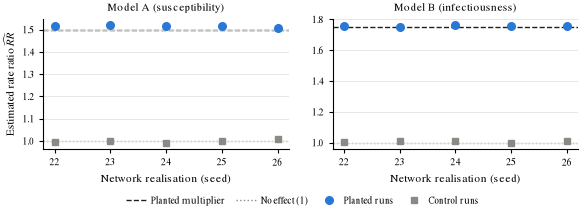

Saved figures\fig_stress_tests.pdf


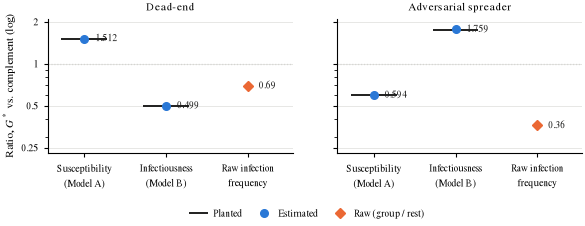

Saved figures\fig_ablations.pdf


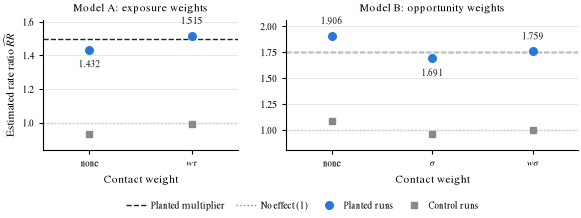

Saved figures\fig_naive_vs_adjusted_local.pdf


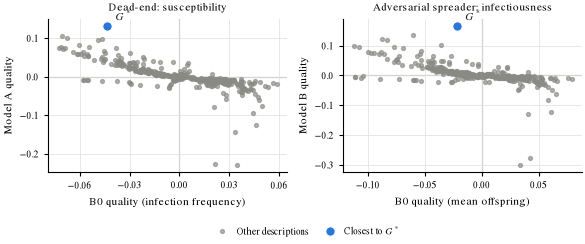

In [54]:
# ============================================================
# 12.6 Figures used in the paper
# ============================================================

from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Output directory and publication styling
# ------------------------------------------------------------

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Approximate ACM two-column text width.
TEXT_WIDTH = 6.9

COLOR_EST = "#2a78d6"
COLOR_RAW = "#eb6834"
COLOR_CTRL = "#8a8a85"
COLOR_TRUTH = "#1f1f1e"

mpl.rcParams.update(
    {
        # Typography
        "font.family": "STIXGeneral",
        "mathtext.fontset": "stix",
        "font.size": 8,
        "axes.titlesize": 8,
        "axes.labelsize": 8,
        "legend.fontsize": 7,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,

        # Axes
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 0.8,

        # Grid
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": "#e3e3e0",
        "grid.linewidth": 0.6,
        "grid.linestyle": "-",

        # Lines
        "lines.linewidth": 1.2,

        # Export
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.03,
        "savefig.dpi": 300,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,

        # Background
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    }
)


def save_figure(fig, name):
    """Save both vector PDF and high-resolution PNG."""
    pdf_path = FIG_DIR / f"{name}.pdf"
    png_path = FIG_DIR / f"{name}.png"

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
    )

    fig.savefig(
        png_path,
        bbox_inches="tight",
        dpi=300,
    )

    print("Saved", pdf_path)


def style_ax(ax, grid_axis="y"):
    """Apply the common paper style to one axis."""
    ax.grid(
        True,
        axis=grid_axis,
        zorder=0,
    )

    ax.tick_params(
        length=3,
        width=0.8,
    )

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)


def bottom_legend(
    fig,
    ax,
    ncol,
    y=-0.01,
):
    """Place a shared legend below both panels."""

    handles, labels = ax.get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(0.5, y),
        ncol=ncol,
        frameon=False,
        columnspacing=1.2,
        handletextpad=0.5,
    )


def label_point(
    ax,
    x,
    value,
    text,
    *,
    above=True,
):
    """Add a compact numerical value label."""

    ax.annotate(
        text,
        (x, value),
        xytext=(
            0,
            7 if above else -7,
        ),
        textcoords="offset points",
        ha="center",
        va=(
            "bottom"
            if above
            else "top"
        ),
        fontsize=7,
        color=COLOR_TRUTH,
    )


def truth_tick(
    ax,
    x,
    value,
    *,
    half_width=0.28,
    label=None,
):
    """Draw the short black horizontal line representing truth."""

    ax.hlines(
        value,
        x - half_width,
        x + half_width,
        color=COLOR_TRUTH,
        linewidth=1.4,
        zorder=2,
        label=label,
    )


# ============================================================
# Figure 1:
# Exact planted subgroup G* across five network realisations
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(TEXT_WIDTH, 2.20),
)

panels = [
    (
        axes[0],
        "A",
        NETWORK_MODEL_A_MULTIPLIER,
        "Model A (susceptibility)",
    ),
    (
        axes[1],
        "B",
        NETWORK_MODEL_B_MULTIPLIER,
        "Model B (infectiousness)",
    ),
]

for ax, model, truth, title in panels:

    data = local_recovery.query(
        "model == @model"
    )

    planted = (
        data.query(
            "condition == 'planted'"
        )
        .sort_values(
            "network_seed"
        )
    )

    control = (
        data.query(
            "condition == 'control'"
        )
        .sort_values(
            "network_seed"
        )
    )

    x = np.arange(
        len(planted)
    )

    # True planted multiplier.
    ax.axhline(
        truth,
        color=COLOR_TRUTH,
        linewidth=1.0,
        linestyle="--",
        label="Planted multiplier",
        zorder=1,
    )

    # Null / no-effect line.
    ax.axhline(
        1.0,
        color=COLOR_CTRL,
        linewidth=1.0,
        linestyle=":",
        label="No effect (1)",
        zorder=1,
    )

    # Planted runs.
    ax.plot(
        x,
        planted["gstar_rr"],
        linestyle="none",
        marker="o",
        color=COLOR_EST,
        markersize=5.5,
        label="Planted runs",
        zorder=3,
    )

    # Matched controls.
    ax.plot(
        x,
        control["gstar_rr"],
        linestyle="none",
        marker="s",
        color=COLOR_CTRL,
        markersize=4.7,
        label="Control runs",
        zorder=3,
    )

    ax.set_xticks(
        x,
        [
            str(seed)
            for seed
            in planted["network_seed"]
        ],
    )

    ax.set_xlabel(
        "Network realisation (seed)"
    )

    ax.set_title(title)

    style_ax(ax)

axes[0].set_ylabel(
    r"Estimated rate ratio $\widehat{RR}$"
)

fig.subplots_adjust(
    bottom=0.29,
    wspace=0.18,
)

bottom_legend(
    fig,
    axes[0],
    ncol=4,
)

save_figure(
    fig,
    "fig_cross_network",
)

plt.show()


# ============================================================
# Figure 2:
# Mechanism stress tests on exact G*
# ============================================================

stress_raw = {
    "Dead-end": dead_end_naive,
    "Adversarial spreader":
        adversarial_naive,
}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(TEXT_WIDTH, 2.35),
    sharey=True,
)

categories = [
    "Susceptibility\n(Model A)",
    "Infectiousness\n(Model B)",
    "Raw infection\nfrequency",
]

for ax, scenario in zip(
    axes,
    [
        "Dead-end",
        "Adversarial spreader",
    ],
):

    scenario_rows = (
        local_stress.query(
            "scenario == @scenario "
            "and knowledge == 'given'"
        )
    )

    row_a = (
        scenario_rows
        .query(
            "model == 'A'"
        )
        .iloc[0]
    )

    row_b = (
        scenario_rows
        .query(
            "model == 'B'"
        )
        .iloc[0]
    )

    truths = [
        float(
            row_a["true"]
        ),
        float(
            row_b["true"]
        ),
    ]

    estimates = [
        float(
            row_a["gstar_rr"]
        ),
        float(
            row_b["gstar_rr"]
        ),
    ]

    raw_ratio = (
        stress_raw[
            scenario
        ]["group"]
        / stress_raw[
            scenario
        ]["rest"]
    )

    # Model A / Model B estimates.
    for x, (
        truth,
        estimate,
    ) in enumerate(
        zip(
            truths,
            estimates,
        )
    ):

        truth_tick(
            ax,
            x,
            truth,
            label=(
                "Planted"
                if x == 0
                else None
            ),
        )

        ax.plot(
            x,
            estimate,
            linestyle="none",
            marker="o",
            color=COLOR_EST,
            markersize=5.5,
            zorder=3,
            label=(
                "Estimated"
                if x == 0
                else None
            ),
        )

        # Numerical estimate.
        ax.annotate(
            f"{estimate:.3f}",
            (
                x,
                estimate,
            ),
            xytext=(8, 0),
            textcoords="offset points",
            va="center",
            fontsize=7,
            color=COLOR_TRUTH,
        )

    # Raw infection-frequency ratio.
    ax.plot(
        2,
        raw_ratio,
        linestyle="none",
        marker="D",
        color=COLOR_RAW,
        markersize=5.5,
        zorder=3,
        label="Raw (group / rest)",
    )

    ax.annotate(
        f"{raw_ratio:.2f}",
        (
            2,
            raw_ratio,
        ),
        xytext=(8, 0),
        textcoords="offset points",
        va="center",
        fontsize=7,
        color=COLOR_TRUTH,
    )

    # Null ratio.
    ax.axhline(
        1.0,
        color=COLOR_CTRL,
        linewidth=0.8,
        linestyle=":",
        zorder=1,
    )

    ax.set_yscale(
        "log"
    )

    ax.set_ylim(
        0.23,
        2.10,
    )

    ax.set_yticks(
        [
            0.25,
            0.5,
            1.0,
            2.0,
        ],
        [
            "0.25",
            "0.5",
            "1",
            "2",
        ],
    )

    ax.yaxis.set_minor_formatter(
        plt.NullFormatter()
    )

    ax.set_xticks(
        range(3),
        categories,
    )

    ax.set_xlim(
        -0.45,
        2.55,
    )

    ax.set_title(
        scenario
    )

    style_ax(ax)

axes[0].set_ylabel(
    r"Ratio, $G^*$ vs. complement (log)"
)

fig.subplots_adjust(
    bottom=0.31,
    wspace=0.18,
)

bottom_legend(
    fig,
    axes[0],
    ncol=3,
)

save_figure(
    fig,
    "fig_stress_tests",
)

plt.show()


# ============================================================
# Figure 3:
# Contact-weighting ablations
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(TEXT_WIDTH, 2.25),
    gridspec_kw={
        "width_ratios": [
            2,
            3,
        ]
    },
)

ablation_panels = [
    (
        axes[0],
        "Model A: exposure weights",
        model_a_exposure_ablation.rename(
            columns={
                "exposure": "method"
            }
        ),
        {
            "Raw": "none",
            "Weighted": r"$w\tau$",
        },
        NETWORK_MODEL_A_MULTIPLIER,
    ),
    (
        axes[1],
        "Model B: opportunity weights",
        model_b_weighting_ablation,
        {
            "Raw opportunity":
                "none",
            "Susceptibility weighted":
                r"$\sigma$",
            "Susceptibility + edge weighted":
                r"$w\sigma$",
        },
        NETWORK_MODEL_B_MULTIPLIER,
    ),
]

for (
    ax,
    title,
    table,
    labels,
    truth,
) in ablation_panels:

    methods = list(
        labels
    )

    x = np.arange(
        len(methods)
    )

    planted = (
        table.query(
            "condition == 'Planted'"
        )
        .set_index(
            "method"
        )
        .loc[
            methods,
            "rate_ratio",
        ]
    )

    control = (
        table.query(
            "condition == 'Control'"
        )
        .set_index(
            "method"
        )
        .loc[
            methods,
            "rate_ratio",
        ]
    )

    # True planted effect.
    ax.axhline(
        truth,
        color=COLOR_TRUTH,
        linewidth=1.0,
        linestyle="--",
        label="Planted multiplier",
        zorder=1,
    )

    # Null value.
    ax.axhline(
        1.0,
        color=COLOR_CTRL,
        linewidth=1.0,
        linestyle=":",
        label="No effect (1)",
        zorder=1,
    )

    # Planted estimates.
    ax.plot(
        x,
        planted.to_numpy(),
        linestyle="none",
        marker="o",
        color=COLOR_EST,
        markersize=5.5,
        label="Planted runs",
        zorder=3,
    )

    # Control estimates.
    ax.plot(
        x,
        control.to_numpy(),
        linestyle="none",
        marker="s",
        color=COLOR_CTRL,
        markersize=4.7,
        label="Control runs",
        zorder=3,
    )

    # Numerical labels for planted runs.
    for xi, value in zip(
        x,
        planted.to_numpy(),
    ):
        label_point(
            ax,
            xi,
            value,
            f"{value:.3f}",
            above=(
                value >= truth
            ),
        )

    ax.set_xticks(
        x,
        [
            labels[m]
            for m
            in methods
        ],
    )

    ax.set_xlim(
        -0.45,
        len(methods) - 0.55,
    )

    ax.margins(
        y=0.17
    )

    ax.set_xlabel(
        "Contact weight"
    )

    ax.set_title(
        title
    )

    style_ax(ax)

axes[0].set_ylabel(
    r"Estimated rate ratio $\widehat{RR}$"
)

fig.subplots_adjust(
    bottom=0.30,
    wspace=0.20,
)

bottom_legend(
    fig,
    axes[0],
    ncol=4,
)

save_figure(
    fig,
    "fig_ablations",
)

plt.show()


# ============================================================
# Figure 4:
# Naive vs contact-adjusted subgroup quality
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(TEXT_WIDTH, 2.55),
)

scatter_panels = [
    (
        axes[0],
        "Dead-end: susceptibility",
        (
            "Dead-end",
            "A",
            "B0",
        ),
        (
            "Dead-end",
            "A",
            "given",
        ),
        "B0 quality (infection frequency)",
        "Model A quality",
    ),
    (
        axes[1],
        "Adversarial spreader: infectiousness",
        (
            "Adversarial spreader",
            "B",
            "B0",
        ),
        (
            "Adversarial spreader",
            "B",
            "given",
        ),
        "B0 quality (mean offspring)",
        "Model B quality",
    ),
]

for (
    ax,
    title,
    naive_key,
    adjusted_key,
    xlabel,
    ylabel,
) in scatter_panels:

    merged = (
        local_naive_results[
            naive_key
        ][
            [
                "description",
                "quality",
            ]
        ]
        .merge(
            local_stress_results[
                adjusted_key
            ][
                [
                    "description",
                    "quality",
                ]
            ],
            on="description",
            suffixes=(
                "_naive",
                "_adjusted",
            ),
        )
    )

    overlap = (
        merged[
            "description"
        ]
        .map(
            lambda description:
                jaccard(
                    local_mask[
                        description
                    ],
                    planted_mask,
                )
        )
    )

    is_best = (
        overlap
        == overlap.max()
    )

    # Zero reference lines.
    ax.axhline(
        0,
        color=COLOR_CTRL,
        linewidth=0.8,
        zorder=1,
    )

    ax.axvline(
        0,
        color=COLOR_CTRL,
        linewidth=0.8,
        zorder=1,
    )

    # All other subgroup descriptions.
    ax.plot(
        merged.loc[
            ~is_best,
            "quality_naive",
        ],
        merged.loc[
            ~is_best,
            "quality_adjusted",
        ],
        linestyle="none",
        marker="o",
        color=COLOR_CTRL,
        markersize=2.8,
        alpha=0.65,
        label="Other descriptions",
        zorder=2,
    )

    # Closest searchable subgroup to G*.
    ax.plot(
        merged.loc[
            is_best,
            "quality_naive",
        ],
        merged.loc[
            is_best,
            "quality_adjusted",
        ],
        linestyle="none",
        marker="o",
        color=COLOR_EST,
        markersize=6.8,
        markeredgecolor="white",
        markeredgewidth=0.8,
        zorder=3,
        label="Closest to $G^*$",
    )

    # Annotate highlighted subgroup.
    best_row = (
        merged.loc[
            is_best
        ]
        .iloc[0]
    )

    ax.annotate(
        "$G^*$",
        (
            best_row[
                "quality_naive"
            ],
            best_row[
                "quality_adjusted"
            ],
        ),
        xytext=(
            6,
            4,
        ),
        textcoords="offset points",
        fontsize=8,
        color=COLOR_TRUTH,
    )

    ax.set_xlabel(
        xlabel
    )

    ax.set_ylabel(
        ylabel
    )

    ax.set_title(
        title
    )

    ax.xaxis.set_major_locator(
        plt.MaxNLocator(5)
    )

    style_ax(
        ax,
        grid_axis="both",
    )

fig.subplots_adjust(
    bottom=0.28,
    wspace=0.23,
)

bottom_legend(
    fig,
    axes[0],
    ncol=2,
)

save_figure(
    fig,
    "fig_naive_vs_adjusted_local",
)

plt.show()

### 12.7 Final results export


In [55]:

# ============================================================
# 12.7 Export the final reported results
# ============================================================

import json


def _jsonable(value):
    if isinstance(value, pd.DataFrame):
        return [
            _jsonable(row)
            for row
            in value.to_dict(
                orient="records"
            )
        ]

    if isinstance(value, dict):
        return {
            str(key): _jsonable(item)
            for key, item
            in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            _jsonable(item)
            for item
            in value
        ]

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(
        value,
        (np.floating, float),
    ):
        return (
            None
            if not np.isfinite(value)
            else float(value)
        )

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, np.ndarray):
        return _jsonable(
            value.tolist()
        )

    return value


household_size_counts = (
    people.groupby("household_id")
    .size()
    .value_counts()
    .sort_index()
)

household_type_counts = (
    people.groupby("household_id")[
        "household_type"
    ]
    .first()
    .value_counts()
)

results_final = {
    "population": {
        "n_nodes": N_NODES,
        "n_households": int(
            people["household_id"].nunique()
        ),
        "mean_household_size": float(
            people.groupby(
                "household_id"
            ).size().mean()
        ),
        "households_by_size": (
            household_size_counts.to_dict()
        ),
        "households_by_type": (
            household_type_counts.to_dict()
        ),
    },

    "network": {
        "household_transmission_multiplier":
            HOUSEHOLD_TRANSMISSION_MULTIPLIER,
        "realisations":
            network_summary,
    },

    "calibration": {
        "target_attack_rate":
            TARGET_ATTACK_RATE,
        "calibrated_p":
            CALIBRATED_P,
        "validation_mean":
            validation_attack_rates.mean(),
        "validation_sd":
            validation_attack_rates.std(
                ddof=1
            ),
        "per_network":
            network_attack_summary,
    },

    "simulation": {
        "recovery_probability":
            RECOVERY_PROB,
        "minor_outbreak_threshold":
            MIN_MAJOR_ATTACK_RATE,
        "planted_description":
            STRESS_TARGET,
        "planted_size":
            int(planted_mask.sum()),
        "model_a_homogeneous_susceptibility":
            NETWORK_MODEL_A_BASE_SUSCEPTIBILITY,
    },

    "search": {
        "type":
            "local equal-frequency",
        "n_bins":
            N_BINS,
        "min_size":
            MIN_SIZE,
        "jaccard_recovered":
            JACCARD_RECOVERED,
        "n_descriptions_generated":
            len(local_mask),
        "n_descriptions_evaluable":
            len(local_eval_masks),
        "root_age_cut_points":
            root_cut_points,
        "smoker_age_cut_points":
            smoker_cut_points,
        "closest_description":
            best_possible_description,
        "closest_jaccard":
            jaccard(
                best_possible_mask,
                planted_mask,
            ),
        "closest_size":
            int(best_possible_mask.sum()),
    },

    "cross_network":
        local_recovery,

    "stress_tests": {
        "model_results":
            local_stress,
        "raw_infection_frequency": {
            "dead_end":
                dead_end_naive,
            "adversarial":
                adversarial_naive,
        },
    },

    "naive_baselines":
        local_naive,

    "ablations": {
        "model_a":
            model_a_exposure_ablation,
        "model_b":
            model_b_weighting_ablation,
    },
}


RESULTS_PATH = Path(
    "results_final.json"
)

RESULTS_PATH.write_text(
    json.dumps(
        _jsonable(
            results_final
        ),
        indent=2,
    )
)

print(
    "Wrote",
    RESULTS_PATH.resolve(),
)

print(
    "Figures in",
    FIG_DIR.resolve(),
)


Wrote C:\Users\User\Desktop\sir_graph_emm\sir-graph-emm\notebooks\results_final.json
Figures in C:\Users\User\Desktop\sir_graph_emm\sir-graph-emm\notebooks\figures
